#### Integrantes: Javiera Freire, Isidora Riquelme, Benjamín Soto.

## Resumen entregables
- **Dataset:** https://huggingface.co/datasets/aharley/rvl_cdip/tree/main/data
- **Github:** https://github.com/bsotoh/DocFlow_AI
- **Aplicación:** https://docflow-ai-bsotoh.streamlit.app

## **Descripción del proyecto**
### Problema y motivación

Hoy en día, la mayoría de las organizaciones manejan grandes cantidades de documentos, y clasificarlos manualmente es un proceso lento. A partir de esto se genera una idea de mejora, en donde las facturas, cartas, formularios e informes deben identificarse y organizarse correctamente para facilitar su almacenamiento y posterior búsqueda.
Si la tarea depende de una o más personas, existe la posibilidad de que se generen errores de clasificación, retrasos y dificultades para encontrar información. Entonces es por esto que creemos que es bastante útil contar con herramientas que permitan automatizar una primera identificación de los documentos.


### Propósito de la app DocFlow AI

Dado esta problemática, como grupo, desarrollamos la aplicación web DocFlow AI, que nos permite identificar automáticamente diferentes tipos de documentos mediante imágenes. Para el desarrollo de esta, utilizamos modelos de inteligencia artificial preentrenados que clasifican los documentos en 16 categorías de documentos. Además, un punto clave de esta aplicación es que incorporamos la IA Gemini, la cual entrega recomendaciones que ayuden a organizar y revisar los documentos según su clasificación. De esta manera, esperamos que clasificar documentos sea más fácil y requiera menos esfuerzo.


### Objetivo General

El objetivo general es desarrollar una aplicación web interactiva, la cual permita clasificar de manera automática diferentes tipos de documentos a través de modelos de inteligencia artificial preentrenados, teniendo también recomendaciones generadas por Gemini para apoyar su organización y revisión.


### Objetivos específicos
1. Analizar y preparar el dataset llamado RVL-CDIP, identificando las 16 categorías de documentos y las características principales que tienen sus imágenes.
2. Implementar y posteriormente comparar los modelos preentrenados EfficientNet-B0 y ResNet50, para así determinar cuál presenta mejores resultados al clasificar los documentos.
3. Evaluar el desempeño de ambos modelos a través de métricas como accuracy, precision, recall y F1-score, teniendo en cuenta también sus matrices de confusión.
4. Desarrollar una aplicación web interactiva que permita cargar documentos y visualizar el resultado de su clasificación, nivel de confianza y probabilidad documento.
5. Integrar Gemini para que genere recomendaciones las cuales ayuden a organizar y revisar los documentos según los resultados de la clasificación.
6. Publicar DocFlow AI en internet para que las personas puedan acceder a sus funcionalidades.


### 1. Configuración inicial

#### 1.1 Librerías, semilla y GPU

In [1]:
import os, glob, random, warnings, tarfile, time, shutil
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import shutil

import tensorflow as tf
from tensorflow import keras
from keras import layers

from rich.console import Console
from rich.table import Table

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

# Semilla para reproducibilidad
SEED = 2026

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
tf.get_logger().setLevel("ERROR")

# Corroborar que la GPU está disponible y funcionando correctamente
print("TensorFlow:", tf.__version__)
print("Semilla:", SEED)

gpus = tf.config.list_physical_devices("GPU")
print("GPU detectadas:", gpus)

assert len(gpus) > 0, "TensorFlow no detecta ninguna GPU."

# Comprobar que se realiza un cálculo en GPU
with tf.device("/GPU:0"):
    a = tf.random.normal((512, 512))
    b = tf.random.normal((512, 512))
    resultado = tf.matmul(a, b)

print("Operación ejecutada en:", resultado.device)

assert "GPU:0" in resultado.device.upper(), "La operación no utilizó GPU."

print("\nLibrerías cargadas correctamente.")
print("GPU ACTIVA Y FUNCIONANDO CORRECTAMENTE.")



TensorFlow: 2.10.1
Semilla: 2026
GPU detectadas: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Operación ejecutada en: /job:localhost/replica:0/task:0/device:GPU:0

Librerías cargadas correctamente.
GPU ACTIVA Y FUNCIONANDO CORRECTAMENTE.


### 2. Carga y exploración de datos

#### 2.1.  Descripción y origen del dataset

Para desarrollar la aplicación DocFlow AI utilizamos el conjunto de datos **RVL-CDIP**, el cual fue creado por Adam W. Harley, Alex Ufkes y Konstantinos G. Derpanis en el año 2015, cuyo objetivo es facilitar la investigación y el desarrollo de modelos capaces de clasificar documentos a partir de imágenes.

El presente dataset contiene documentos escaneados de distintas categorías, como facturas, cartas, formularios, manuscritos e informes científicos. Su origen se relaciona con la colección IIT-CDIP, la cual está compuesta por documentos provenientes de la industria tabacalera estadounidense.

**Ficha técnica del dataset:**

- **Nombre:** RVL-CDIP (Ryerson Vision Lab Complex Document Information Processing).
- **Autores:** Adam W. Harley, Alex Ufkes y Konstantinos G. Derpanis.
- **Año de publicación:** 2015.
- **Cantidad total:** 400.000 imágenes.
- **Número de categorías:** 16.
- **Imágenes por categoría:** 25.000.
- **Formato:** documentos escaneados, principalmente en escala de grises.
- **División original:** En un inicio, RVL-CDIP contiene 320.000 imágenes de entrenamiento, 40.000 de validación y 40.000 de prueba. Para nuestro proyecto, se utilizó una muestra aleatoria estratificada del 40% de entrenamiento (128.000 imágenes) y validación (16.000 imágenes), manteniendo el conjunto de prueba completo, con 39.999 imágenes válidas debido a un archivo que presentó problemas de lectura.
- **Idioma predominante:** inglés.
- **Licencia:** Hugging Face la identifica como `other`. Los documentos provienen de una colección con condiciones particulares de uso, por lo que no debemos asumir que todos tienen una licencia abierta.

**Fuente del dataset:** (https://huggingface.co/datasets/aharley/rvl_cdip/tree/main/data)

#### 2.2. Ubicación y verificación del dataset
**Objetivo:** Comprobaremos que se encuentran los cuatro archivos necesarios para obtener los datos, junto con revisar sus tamaños antes de procesar las imágenes.


In [2]:
# Buscar la carpeta Datos
carpetas_posibles = []

for base in [Path.cwd(), *Path.cwd().parents]:
    carpetas_posibles.extend([
        base / "Datos",
        base / "Talleres" / "Certamen 1" / "Datos"
    ])

ruta_datos = next(
    (ruta for ruta in carpetas_posibles
     if (ruta / "rvl-cdip.tar.gz").is_file()),
    None
)

assert ruta_datos is not None, "No se encontró la carpeta Datos."

ruta_datos = ruta_datos.resolve()

print("Ruta del dataset:", ruta_datos)

# Verificar archivos necesarios
archivos = ["rvl-cdip.tar.gz", "train.txt", "val.txt", "test.txt"]

print("\nARCHIVOS DEL DATASET")
print("=" * 40)

for archivo in archivos:
    ruta = ruta_datos / archivo
    assert ruta.is_file(), f"No se encontró: {archivo}"
    print(f"{archivo}: OK")

print("\nVerificación del dataset completada.")


Ruta del dataset: C:\Users\benja\Documents\IA Generativa\Talleres\Certamen 1\Datos

ARCHIVOS DEL DATASET
rvl-cdip.tar.gz: OK
train.txt: OK
val.txt: OK
test.txt: OK

Verificación del dataset completada.


#### 2.3. Carga y análisis de etiquetas
**Objetivo:** se cargarán las etiquetas del dataset, también se identificarán las 16 categorías documentales y se verificará la cantidad de imágenes destinadas a entrenamiento, validación y prueba.

In [3]:
# Rutas de los archivos de etiquetas
TRAIN = ruta_datos / "train.txt"                     # imágenes de entrenamiento
VAL = ruta_datos / "val.txt"                         # imágenes de validación
TEST = ruta_datos / "test.txt"                       # imágenes de prueba

# Cargar las rutas y etiquetas de cada imagen
train_df = pd.read_csv(TRAIN, sep=r"\s+", header=None, names=["imagen", "clase"])
val_df = pd.read_csv(VAL, sep=r"\s+", header=None, names=["imagen", "clase"])
test_df = pd.read_csv(TEST, sep=r"\s+", header=None, names=["imagen", "clase"])

# Nombres de las 16 clases del dataset
CLASES = [
    "Carta", "Formulario", "Correo electrónico", "Manuscrito",
    "Publicidad", "Informe científico", "Publicación científica",
    "Especificación", "Carpeta", "Noticia", "Presupuesto",
    "Factura", "Presentación", "Cuestionario", "Currículum",
    "Memorándum"
]

# Resumen de imágenes por conjunto
resumen = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validación", "Prueba"],
    "Imágenes": [len(train_df), len(val_df), len(test_df)]
})

resumen.loc[len(resumen)] = ["Total", resumen["Imágenes"].sum()]

print("RESUMEN DEL DATASET RVL-CDIP")
display(
    resumen.style
    .hide(axis="index")
    .format({"Imágenes": "{:,.0f}"})
    .set_properties(**{"text-align": "left", "padding": "6px"})
)

# Mostrar las primeras observaciones
print("\nPRIMERAS OBSERVACIONES DEL ENTRENAMIENTO")
display(train_df.head())

# Mostrar las 16 categorías en una tabla
clases_df = pd.DataFrame({
    "Código": range(len(CLASES)),
    "Categoría": CLASES
})

print("\nCATEGORÍAS DEL DATASET RVL-CDIP")
display(
    clases_df.style
    .hide(axis="index")
    .set_properties(**{
        "text-align": "left",
        "padding": "6px"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [("text-align", "left")]
        }
    ])
)


RESUMEN DEL DATASET RVL-CDIP


Conjunto,Imágenes
Entrenamiento,"320,000"
Validación,"40,000"
Prueba,"40,000"
Total,"400,000"



PRIMERAS OBSERVACIONES DEL ENTRENAMIENTO


,imagen,clase
0,imagesq/q/o/c/qoc54c00/80035521.tif,15
1,imagese/e/w/c/ewc23d00/513280028.tif,1
2,imagesw/w/b/t/wbt26e00/2053453161.tif,7
3,imagesm/m/k/m/mkm05e00/2040792992_2040792994.tif,10
4,imageso/o/e/x/oex80d00/522787731+-7732.tif,3



CATEGORÍAS DEL DATASET RVL-CDIP


Código,Categoría
0,Carta
1,Formulario
2,Correo electrónico
3,Manuscrito
4,Publicidad
5,Informe científico
6,Publicación científica
7,Especificación
8,Carpeta
9,Noticia


#### 2.4. Distribución de las clases
**Objetivo:** Analizaremos la cantidad de imágenes por categoría en los conjuntos de entrenamiento, validación y prueba, identificando así los posibles desbalances que puedan afectar el rendimiento del modelo.

Categoría,Train,Val,Test,Total
Carta,"20,106","2,430","2,464","25,000"
Formulario,"19,957","2,537","2,506","25,000"
Correo electrónico,"19,954","2,530","2,516","25,000"
Manuscrito,"20,034","2,434","2,532","25,000"
Publicidad,"19,963","2,522","2,515","25,000"
Informe científico,"19,994","2,508","2,498","25,000"
Publicación científica,"19,902","2,526","2,572","25,000"
Especificación,"19,997","2,531","2,472","25,000"
Carpeta,"20,022","2,451","2,527","25,000"
Noticia,"20,011","2,526","2,463","25,000"


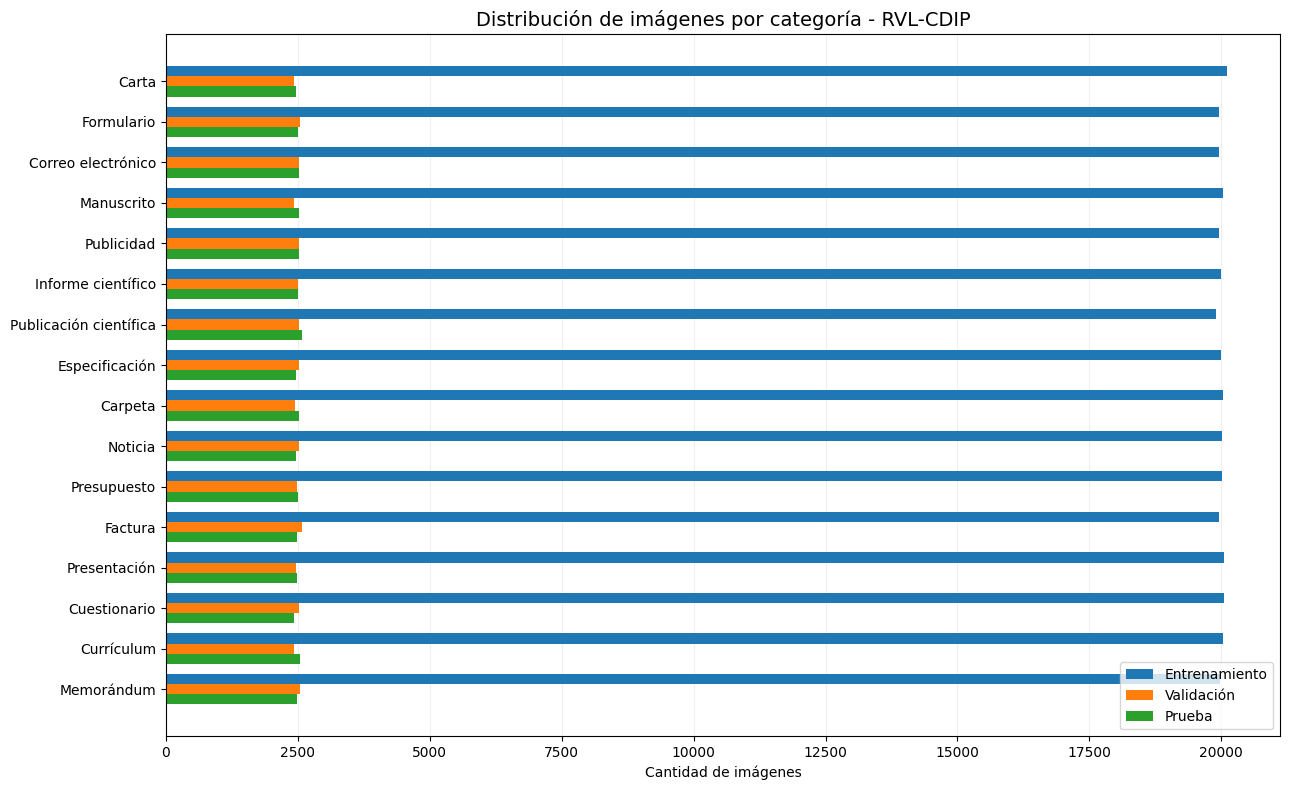

Imágenes por clase (mínimo): 25,000
Imágenes por clase (máximo): 25,000
El dataset está equilibrado entre las 16 categorías.


In [4]:
# Contar las imágenes de cada clase
distribucion = pd.DataFrame({
    "Categoría": CLASES,
    "Train": train_df["clase"].value_counts().reindex(range(16), fill_value=0).values,
    "Val": val_df["clase"].value_counts().reindex(range(16), fill_value=0).values,
    "Test": test_df["clase"].value_counts().reindex(range(16), fill_value=0).values
})

distribucion["Total"] = distribucion[["Train", "Val", "Test"]].sum(axis=1)

# Mostrar la distribución en una tabla
display(
    distribucion.style
    .hide(axis="index")
    .format({c: "{:,.0f}" for c in ["Train", "Val", "Test", "Total"]})
)

# Gráfico de distribución por categoría
fig, ax = plt.subplots(figsize=(13, 8))

y = np.arange(len(CLASES))
ancho = 0.25

ax.barh(y - ancho, distribucion["Train"], ancho, label="Entrenamiento")
ax.barh(y, distribucion["Val"], ancho, label="Validación")
ax.barh(y + ancho, distribucion["Test"], ancho, label="Prueba")

ax.set_yticks(y)
ax.set_yticklabels(CLASES)
ax.invert_yaxis()

ax.set_title("Distribución de imágenes por categoría - RVL-CDIP", fontsize=14)
ax.set_xlabel("Cantidad de imágenes")
ax.legend()
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# Comprobar el balance del dataset
minimo = distribucion["Total"].min()
maximo = distribucion["Total"].max()

print(f"Imágenes por clase (mínimo): {minimo:,}")
print(f"Imágenes por clase (máximo): {maximo:,}")

if minimo == maximo:
    print("El dataset está equilibrado entre las 16 categorías.")
else:
    print("Existen diferencias en la cantidad de imágenes por categoría.")


Como se puede observar el dataset tiene 16 categorías, cada una con 25.000 imágenes, contando así con la misma cantidad de datos por cada categoría. Esto es bueno para el entrenamiento, ya que ninguna categoría tiene mayor cantidad de datos con respecto a las otras. Sin embargo,  puede que algunas sean más difíciles de reconocer debido a sus similitudes con otros tipos de documentos.

#### 2.5. Visualización de imágenes
**Objetivo:** Se revisarán los ejemplos de las distintas categorías para conocer cómo son los documentos y qué diferencias visuales presentan antes de entrenar los modelos.

##### 2.5.1. Extracción de las imágenes

In [5]:
from sklearn.model_selection import train_test_split

# Seleccionar el 40% de los datos de entrenamiento y validación
PORCENTAJE_MUESTRA = 0.40

train_muestra_df, _ = train_test_split(
    train_df,
    train_size=PORCENTAJE_MUESTRA,
    stratify=train_df["clase"],
    random_state=SEED
)

val_muestra_df, _ = train_test_split(
    val_df,
    train_size=PORCENTAJE_MUESTRA,
    stratify=val_df["clase"],
    random_state=SEED
)

# Mantener completo el conjunto de prueba
test_muestra_df = test_df.copy()

# Definir las imágenes que necesitamos
datos_seleccionados = pd.concat(
    [train_muestra_df, val_muestra_df, test_muestra_df],
    ignore_index=True
)

rutas_requeridas = {
    f"images/{ruta}"
    for ruta in datos_seleccionados["imagen"]
}

# Rutas de extracción
archivo_tar = ruta_datos / "rvl-cdip.tar.gz"
ruta_imagenes = ruta_datos / "imagenes"
ruta_imagenes.mkdir(parents=True, exist_ok=True)

# Identificar los archivos que todavía faltan
pendientes = {
    ruta for ruta in rutas_requeridas
    if not (ruta_imagenes / ruta).is_file()
}

print("IMÁGENES SELECCIONADAS")
print("=" * 45)
print(f"Entrenamiento: {len(train_muestra_df):,}")
print(f"Validación:    {len(val_muestra_df):,}")
print(f"Prueba:        {len(test_muestra_df):,}")
print(f"Total:         {len(rutas_requeridas):,}")

# Extraer únicamente los archivos necesarios
extraidas = 0

if pendientes:

    with tarfile.open(archivo_tar, "r|gz") as tar:

        for archivo in tar:

            if not archivo.isfile():
                continue

            if archivo.name not in pendientes:
                continue

            destino = ruta_imagenes / archivo.name
            destino.parent.mkdir(parents=True, exist_ok=True)

            temporal = destino.with_name(destino.name + ".parcial")

            with tar.extractfile(archivo) as origen:
                with open(temporal, "wb") as salida:
                    shutil.copyfileobj(origen, salida)

            temporal.replace(destino)

            pendientes.remove(archivo.name)
            extraidas += 1

            if extraidas % 20000 == 0:
                print(f"Imágenes extraídas: {extraidas:,}")

            if not pendientes:
                break

assert not pendientes, (
    f"No se encontraron {len(pendientes)} imágenes en el archivo."
)

print("\nEXTRACCIÓN FINALIZADA")
print("=" * 45)
print(f"Imágenes nuevas: {extraidas:,}")
print(f"Imágenes disponibles: {len(rutas_requeridas):,}")
print("Muestra preparada correctamente.")


IMÁGENES SELECCIONADAS
Entrenamiento: 128,000
Validación:    16,000
Prueba:        40,000
Total:         184,000
Imágenes extraídas: 20,000
Imágenes extraídas: 40,000
Imágenes extraídas: 60,000
Imágenes extraídas: 80,000
Imágenes extraídas: 100,000
Imágenes extraídas: 120,000
Imágenes extraídas: 140,000
Imágenes extraídas: 160,000
Imágenes extraídas: 180,000

EXTRACCIÓN FINALIZADA
Imágenes nuevas: 184,000
Imágenes disponibles: 184,000
Muestra preparada correctamente.


Las imágenes se extrajeron una sola vez y quedaron guardadas en la carpeta del proyecto. Para continuar trabajando utilizaremos directamente estos archivos, sin necesidad de repetir la extracción.

### Limitaciones y posibles sesgos del dataset

Como sabemos RVL-CDIP contiene una gran cantidad de imágenes y diferentes tipos de documentos, pero esta presenta algunas limitaciones que debemos considerar al evaluar nuestros modelos:

- **Origen de los documentos:** Las imágenes provienen principalmente de documentos históricos que están relacionados con la industria tabacalera estadounidense. Es por esto que creemos que podrían no representar en su totalidad los documentos utilizados actualmente en otras organizaciones.

- **Idioma:** La mayoría de los documentos están en inglés, por lo que al momento de clasificar un documento en español, el desempeño podría ser diferente.

- **Calidad de las imágenes:** Como son documentos escaneados, algunos pueden tener una baja resolución, manchas o problemas de legibilidad, dificultando así su clasificación.

- **Muestra utilizada:** Debido al largo tiempo de entrenamiento, utilizamos una muestra aleatoria estratificada del 40% de entrenamiento y validación. Aunque mantuvimos la proporción de las categorías, el modelo aprendió utilizando menos imágenes que las disponibles originalmente.

Un punto a tener en cuenta también es que el dataset está equilibrado entre sus 16 categorías, lo cual no quiere decir que represente la distribución real de documentos de una empresa,debido a que algunas categorías pueden aparecer con mucha mayor frecuencia que otras.
Es por estas razones que los resultados obtenidos deben interpretarse considerando el contexto del dataset.

##### 2.5.2. Visualización de ejemplos por categoría
**Objetivo:** Se observará una imagen de cada una de las 16 categorías para conocer cómo son los documentos y qué diferencias presentan entre ellos.

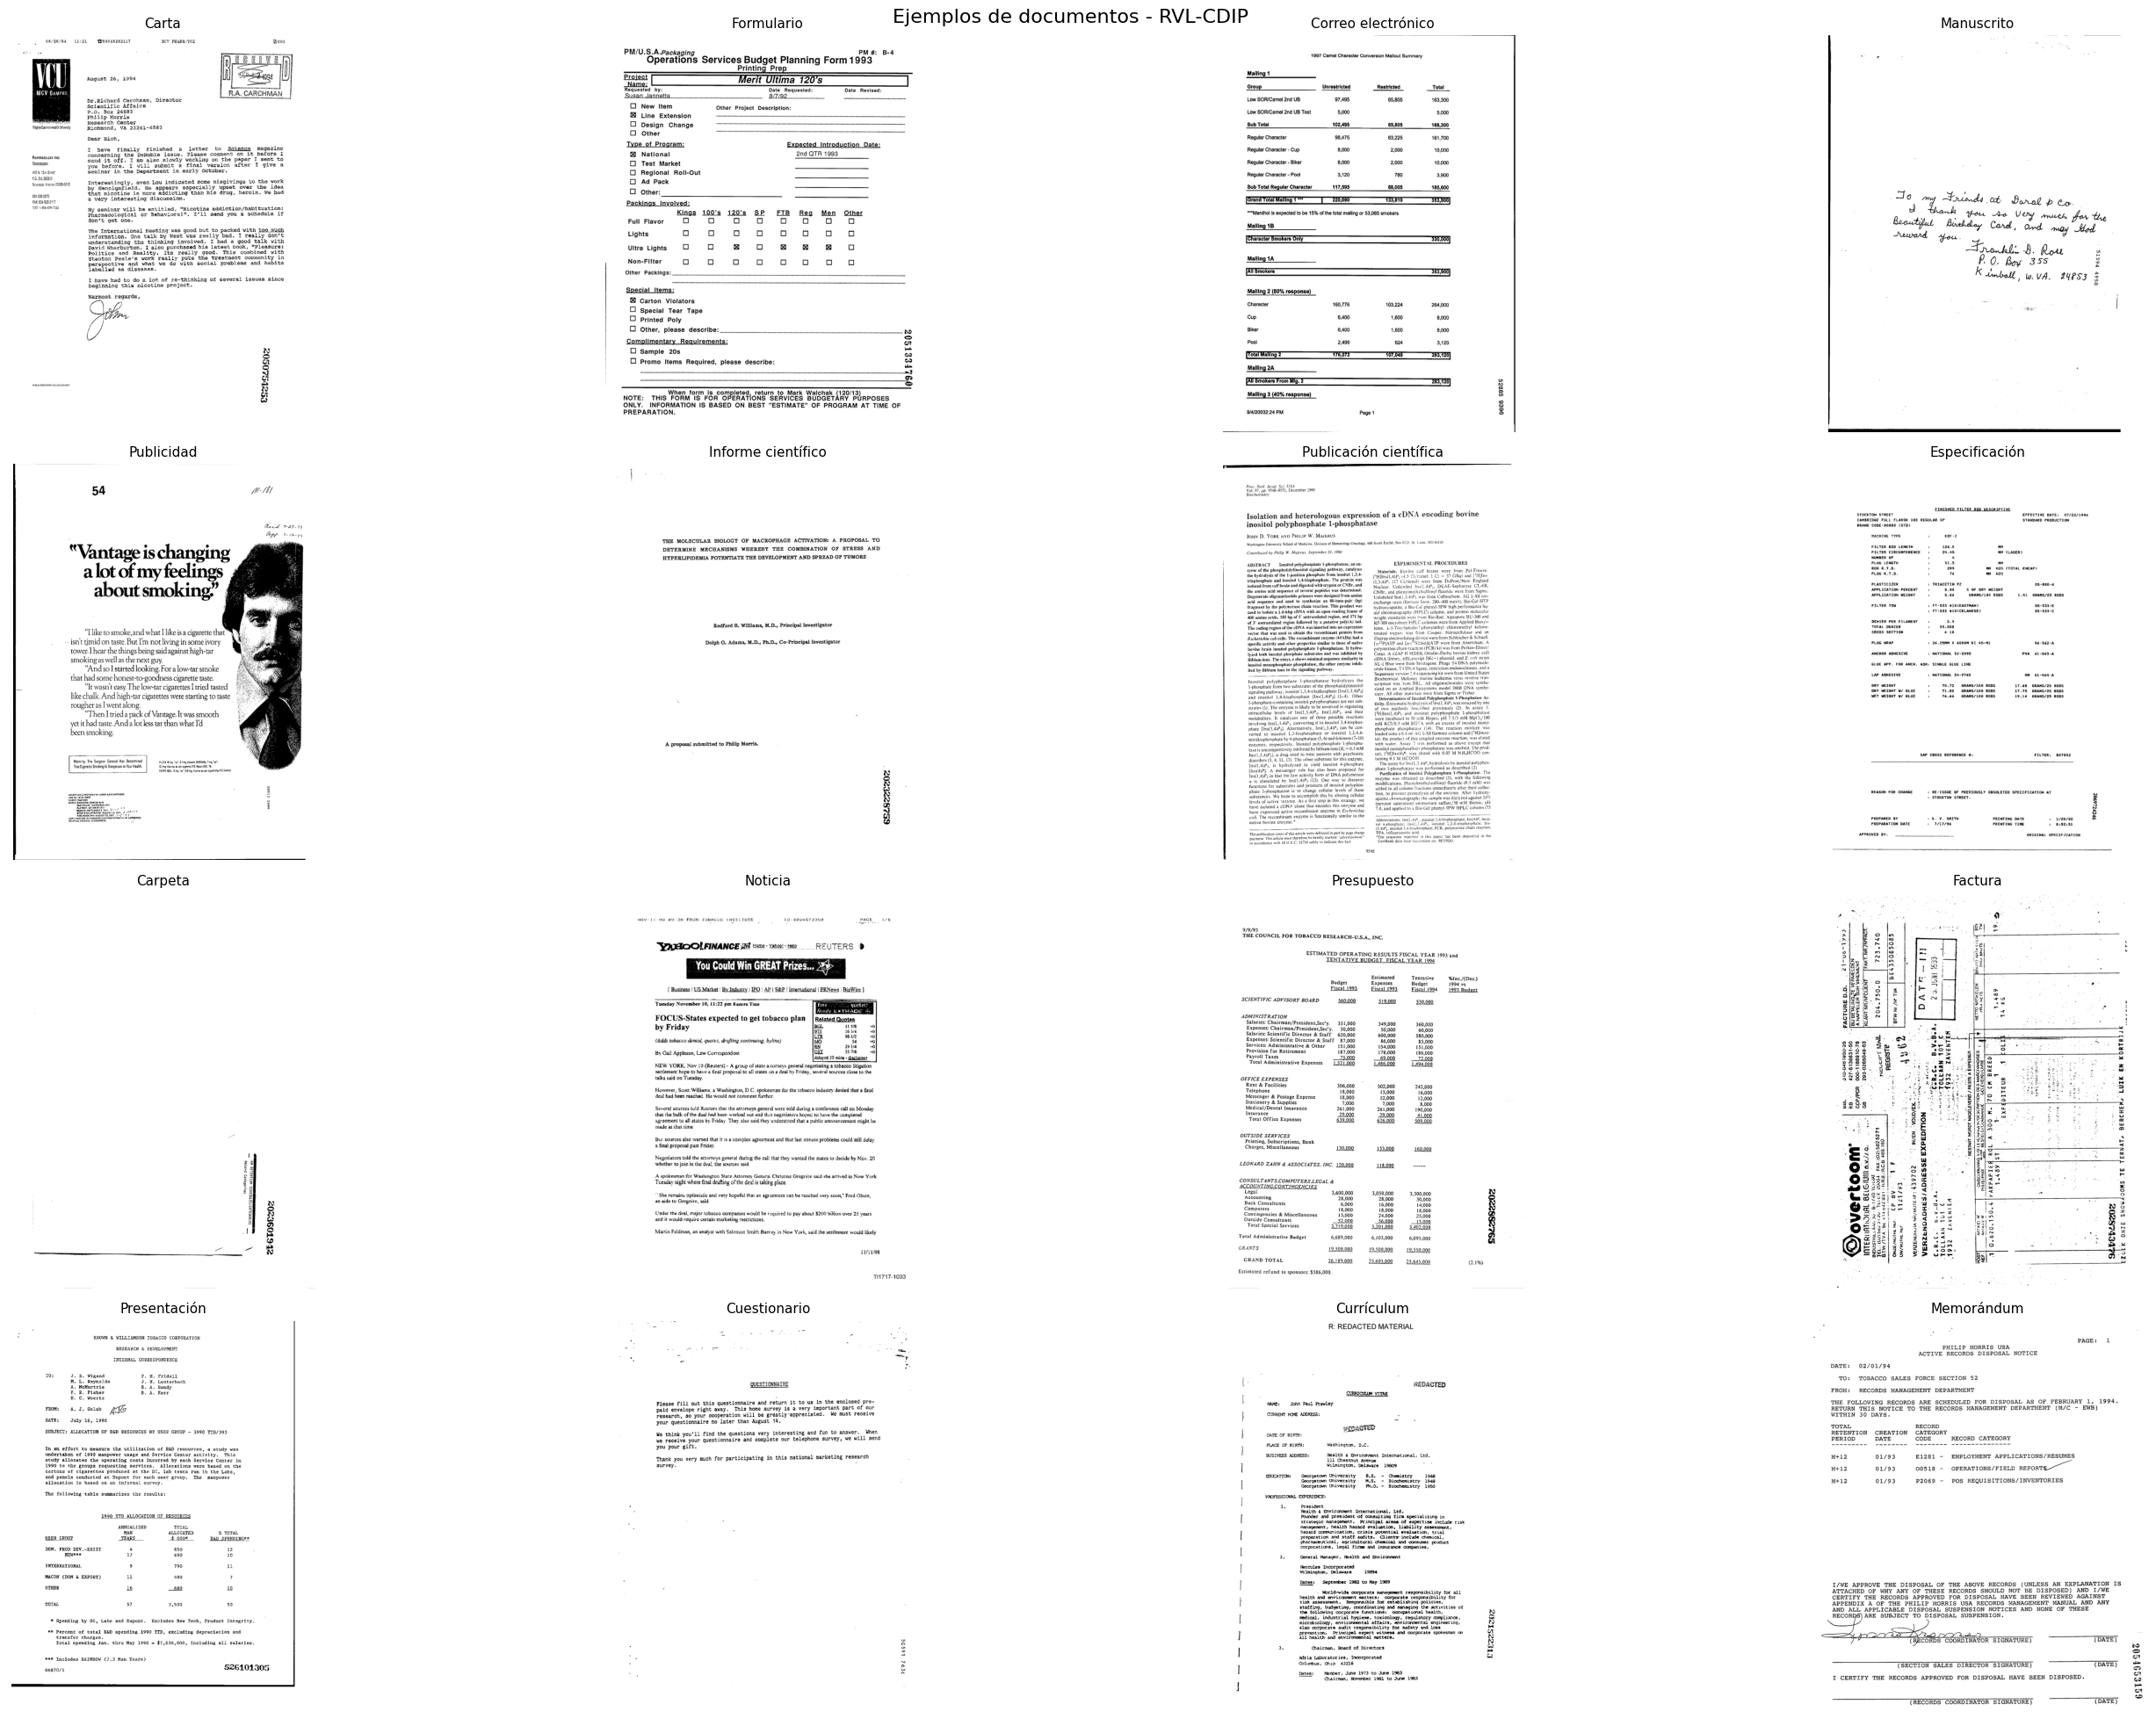

In [6]:
# Seleccionar una imagen aleatoria por categoría
ejemplos = (
    train_muestra_df.groupby("clase")
    .sample(n=1, random_state=SEED)
    .sort_values("clase")
)
# Mostrar las 16 categorías
plt.figure(figsize=(30, 20))

for i, (_, fila) in enumerate(ejemplos.iterrows()):

    # Ubicar la imagen según la estructura del dataset
    ruta_relativa = Path(fila["imagen"])

    posibles_rutas = [
        ruta_datos / "imagenes" / ruta_relativa,
        ruta_datos / "imagenes" / "images" / ruta_relativa
    ]

    ruta = next((p for p in posibles_rutas if p.is_file()), None)

    if ruta is None:
        raise FileNotFoundError(f"No se encontró la imagen: {ruta_relativa}")

    # Abrir la imagen en escala de grises
    with Image.open(ruta) as img:
        imagen = img.convert("L")

    # Visualización similar a la clase
    plt.subplot(4, 4, i + 1)
    plt.imshow(imagen, cmap="gray")
    plt.title(CLASES[int(fila["clase"])], fontsize=11)
    plt.axis("off")

plt.suptitle("Ejemplos de documentos - RVL-CDIP", fontsize=16)
plt.tight_layout()
plt.show()


Al revisar y analizar las imágenes, podemos ver que los documentos tienen formatos bastante distintos. Algunos están girados, otros tienen mucho espacio en blanco y también hay diferencias en la calidad de los escaneos. Además, ciertos documentos se parecen entre sí, lo que podría dificultar su clasificación.

#### 2.6. Calidad y limitaciones de los datos.
**Objetivo:** Se revisarán las características de las imágenes, como sus dimensiones, orientación y formato, para así poder identificar posibles dificultades antes del entrenamiento.

In [7]:
# Seleccionar 10 imágenes aleatorias por categoría
muestra = train_muestra_df.groupby("clase").sample(n=10, random_state=SEED)

resultados = []

# Revisar las características de cada imagen
for _, fila in muestra.iterrows():

    ruta_relativa = Path(fila["imagen"])

    posibles_rutas = [
        ruta_datos / "imagenes" / ruta_relativa,
        ruta_datos / "imagenes" / "images" / ruta_relativa
    ]

    ruta = next((p for p in posibles_rutas if p.is_file()), None)

    if ruta is None:
        resultados.append({
            "Ancho": np.nan, "Alto": np.nan,
            "Formato": "No encontrado",
            "Modo": "No encontrado",
            "Orientación": "Desconocida",
            "Estado": "Error"
        })
        continue

    try:
        with Image.open(ruta) as img:
            ancho, alto = img.size
            formato = img.format
            modo = img.mode
            img.verify()

        orientacion = (
            "Vertical" if alto > ancho else
            "Horizontal" if ancho > alto else
            "Cuadrada"
        )

        resultados.append({
            "Ancho": ancho,
            "Alto": alto,
            "Formato": formato,
            "Modo": modo,
            "Orientación": orientacion,
            "Estado": "OK"
        })

    except Exception:
        resultados.append({
            "Ancho": np.nan, "Alto": np.nan,
            "Formato": "Desconocido",
            "Modo": "Desconocido",
            "Orientación": "Desconocida",
            "Estado": "Error"
        })

# Crear tabla de resultados
calidad_df = pd.DataFrame(resultados)

print("RESUMEN DE LA MUESTRA")
print(f"Imágenes revisadas: {len(calidad_df)}")
print(f"Imágenes con error: {(calidad_df['Estado'] == 'Error').sum()}")

# Analizar dimensiones
print("\nDIMENSIONES DE LAS IMÁGENES (PÍXELES)")

display(
    calidad_df[["Ancho", "Alto"]]
    .agg(["min", "median", "max"])
    .rename(index={
        "min": "Mínimo",
        "median": "Mediana",
        "max": "Máximo"
    })
)

# Analizar orientación y formato
print("\nORIENTACIÓN DE LAS IMÁGENES")
display(calidad_df["Orientación"].value_counts().to_frame("Cantidad"))

print("\nFORMATO Y MODO DE COLOR")
display(
    calidad_df.groupby(["Formato", "Modo"])
    .size()
    .reset_index(name="Cantidad")
)


RESUMEN DE LA MUESTRA
Imágenes revisadas: 160
Imágenes con error: 0

DIMENSIONES DE LAS IMÁGENES (PÍXELES)


,Ancho,Alto
Mínimo,747.0,1000.0
Mediana,762.0,1000.0
Máximo,868.0,1000.0



ORIENTACIÓN DE LAS IMÁGENES


,Cantidad
Orientación,
Vertical,160



FORMATO Y MODO DE COLOR


,Formato,Modo,Cantidad
0,TIFF,L,160


En las 160 imágenes revisadas no se encontraron errores y todas están en escala de grises. Aunque estas tengan la misma altura, algunas tienen diferencias en el ancho y en la orientación del contenido. A partir de esto consideramos que es bastante es importante. debido a que tendremos que adaptar las imágenes a un tamaño común antes del entrenamiento, procurando mantener su forma original para no distorsionar los documentos.

### 3. Preprocesamiento de imágenes

#### 3.1. Preparación de imágenes
**Objetivo:** Se adaptarán las imágenes a una resolución de 384 × 384 píxeles, manteniendo así sus proporciones para evitar que los documentos se deformen.

In [8]:
# Definir el tamaño de entrada
TAMANO_IMG = (384, 384)

# Función para preparar las imágenes
def preparar_imagen(ruta):

    with Image.open(ruta) as imagen:

        # Convertir a RGB (3 canales)
        imagen = imagen.convert("RGB")

        # Redimensionar sin deformar y completar con fondo blanco
        imagen = ImageOps.pad(
            imagen,
            TAMANO_IMG,
            method=Image.Resampling.LANCZOS,
            color=(255, 255, 255)
        )

        # Convertir la imagen a un arreglo numérico
        imagen = np.array(imagen, dtype=np.float32)

    return imagen

print("Preparación de imágenes configurada correctamente.")
print("Resolución:", TAMANO_IMG)


Preparación de imágenes configurada correctamente.
Resolución: (384, 384)


#### 3.2. Preparación de los conjuntos de datos
**Objetivo:** Se seleccionará una muestra aleatoria estratificada del 40% de los datos de entrenamiento y validación, manteniendo la proporción de las 16 categorías. Ambos modelos utilizarán las mismas imágenes para poder comparar sus resultados bajo las mismas condiciones.

In [9]:
carpetas_posibles = [
    ruta_datos / "imagenes",
    ruta_datos / "imagenes" / "images"
]

# Comprobar una imagen de cada conjunto
ejemplos = [
    train_muestra_df["imagen"].iloc[0],
    val_muestra_df["imagen"].iloc[0],
    test_df["imagen"].iloc[0]
]

RUTA_IMG = next(
    (carpeta for carpeta in carpetas_posibles
     if all((carpeta / imagen).is_file() for imagen in ejemplos)),
    None
)

assert RUTA_IMG is not None, "No se encontró la carpeta de imágenes."

# Preparar las rutas y etiquetas
def preparar_datos(df):
    rutas = [str(RUTA_IMG / imagen) for imagen in df["imagen"]]
    etiquetas = df["clase"].to_numpy(dtype=np.int32)
    return rutas, etiquetas

# Utilizar la muestra seleccionada en el punto 2.4.1
X_train, y_train = preparar_datos(train_muestra_df)
X_val, y_val = preparar_datos(val_muestra_df)
X_test, y_test = preparar_datos(test_df)

# Verificar los conjuntos
NUM_CLASES = len(CLASES)

print("CONJUNTOS DE DATOS")
print("=" * 45)

for nombre, rutas, etiquetas in [
    ("Entrenamiento", X_train, y_train),
    ("Validación", X_val, y_val),
    ("Prueba", X_test, y_test)
]:
    print(f"{nombre}: {len(rutas):,} imágenes | {len(etiquetas):,} etiquetas")

print("\nPorcentaje de muestra:", f"{PORCENTAJE_MUESTRA:.0%}")
print("Carpeta de imágenes:", RUTA_IMG)
print("Número de clases:", NUM_CLASES)
print("\nConjuntos preparados correctamente.")


CONJUNTOS DE DATOS
Entrenamiento: 128,000 imágenes | 128,000 etiquetas
Validación: 16,000 imágenes | 16,000 etiquetas
Prueba: 40,000 imágenes | 40,000 etiquetas

Porcentaje de muestra: 40%
Carpeta de imágenes: C:\Users\benja\Documents\IA Generativa\Talleres\Certamen 1\Datos\imagenes\images
Número de clases: 16

Conjuntos preparados correctamente.


#### 3.3. Carga eficiente de imágenes con `tf.data`
**Objetivo:** Se prepararán las imágenes en pequeños grupos para así poder utilizarlos durante el entrenamiento, evitando cargar todo el dataset en memoria y mejorando la velocidad de procesamiento.

In [10]:
# Configuración inicial
LOTE = 16
AUTOTUNE = tf.data.AUTOTUNE

# Función para cargar imágenes TIFF
def cargar_imagen(ruta, etiqueta):

    # Utilizar la función de preparación del punto 3.1
    imagen = tf.numpy_function(
        lambda r: preparar_imagen(r.decode("utf-8")),
        [ruta],
        tf.float32
    )

    # Definir las dimensiones de la imagen
    imagen.set_shape((384, 384, 3))
    etiqueta = tf.cast(etiqueta, tf.int32)

    return imagen, etiqueta


# Función para crear los conjuntos de datos
def crear_dataset(rutas, etiquetas, entrenamiento=False):

    ds = tf.data.Dataset.from_tensor_slices((rutas, etiquetas))

    # Mezclar únicamente los datos de entrenamiento
    if entrenamiento:
        ds = ds.shuffle(
            buffer_size=4096,
            seed=SEED,
            reshuffle_each_iteration=True
        )

    # Cargar y preparar imágenes en paralelo
    ds = ds.map(
        cargar_imagen,
        num_parallel_calls=AUTOTUNE
    )

    # Agrupar imágenes y preparar los siguientes lotes
    ds = ds.batch(LOTE).prefetch(AUTOTUNE)

    return ds


# Crear los conjuntos de datos
train_ds = crear_dataset(X_train, y_train, entrenamiento=True)
val_ds = crear_dataset(X_val, y_val)
test_ds = crear_dataset(X_test, y_test)


# Verificar un lote de entrenamiento
imagenes_lote, etiquetas_lote = next(iter(train_ds.take(1)))

print("VERIFICACIÓN DE LOS LOTES")
print("=" * 45)

print("Dimensiones de las imágenes:", imagenes_lote.shape)
print("Dimensiones de las etiquetas:", etiquetas_lote.shape)
print("Tipo de datos:", imagenes_lote.dtype)
print("Valores mínimo y máximo:",
      float(tf.reduce_min(imagenes_lote)),
      float(tf.reduce_max(imagenes_lote)))

print("\nConjuntos preparados correctamente.")


VERIFICACIÓN DE LOS LOTES
Dimensiones de las imágenes: (16, 384, 384, 3)
Dimensiones de las etiquetas: (16,)
Tipo de datos: <dtype: 'float32'>
Valores mínimo y máximo: 0.0 255.0

Conjuntos preparados correctamente.


#### 3.4. Aumento de datos (Data Augmentation)
**Objetivo:** Ahora se aplicarán pequeñas variaciones a las imágenes de entrenamiento para que el modelo pueda aprender a reconocer documentos con diferentes condiciones de escaneo, sin cambiar su contenido principal.

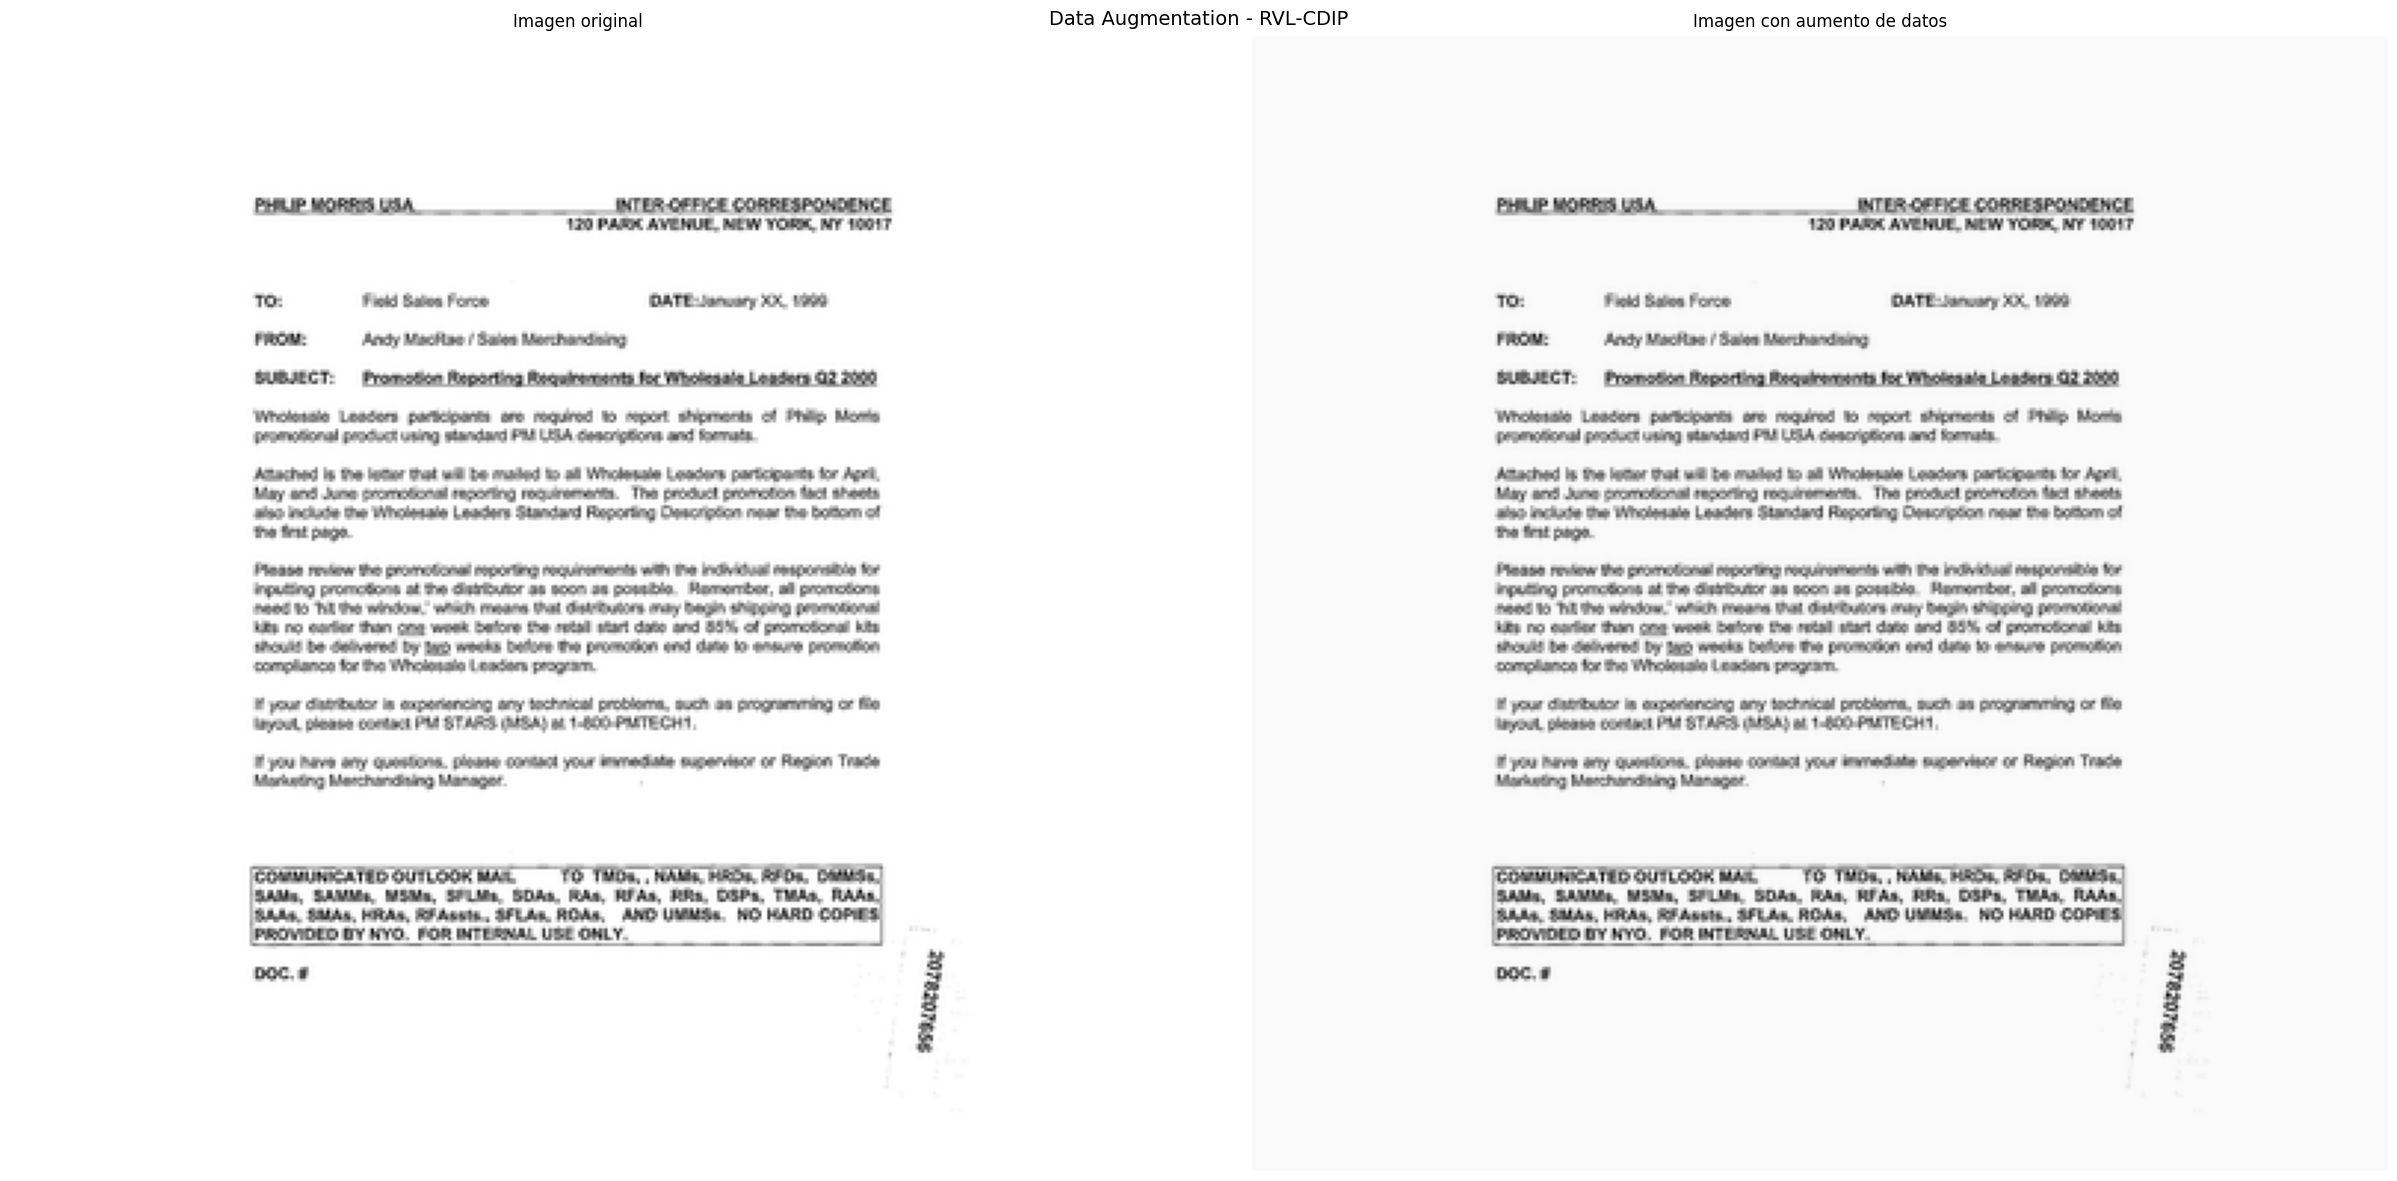

Aumento de datos aplicado únicamente al entrenamiento.
Validación y prueba mantienen sus imágenes originales.


In [ ]:
# Función para aplicar pequeñas variaciones a las imágenes
def aumentar_imagen(imagen, etiqueta):

    # Variación suave de brillo
    imagen = tf.image.random_brightness(imagen, max_delta=8.0)

    # Variación suave de contraste
    imagen = tf.image.random_contrast(imagen, lower=0.95, upper=1.05)

    # Mantener los valores entre 0 y 255
    imagen = tf.clip_by_value(imagen, 0.0, 255.0)

    return imagen, etiqueta


# Reconstruir el conjunto de entrenamiento
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))

# Mezclar las imágenes
train_ds = train_ds.shuffle(
    buffer_size=4096,
    seed=SEED,
    reshuffle_each_iteration=True
)

# Cargar y preparar imágenes en paralelo
train_ds = train_ds.map(
    cargar_imagen,
    num_parallel_calls=AUTOTUNE
)

# Aplicar aumento de datos en paralelo
train_ds = train_ds.map(
    aumentar_imagen,
    num_parallel_calls=AUTOTUNE
)

# Agrupar en lotes y preparar los siguientes
train_ds = train_ds.batch(LOTE).prefetch(AUTOTUNE)


# Visualizar una imagen antes y después del aumento
imagen_original = preparar_imagen(X_train[0])

imagen_aumentada, _ = aumentar_imagen(
    tf.convert_to_tensor(imagen_original),
    tf.constant(y_train[0])
)

plt.figure(figsize=(25, 12))

plt.subplot(1, 2, 1)
plt.imshow(imagen_original.astype(np.uint8))
plt.title("Imagen original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagen_aumentada.numpy().astype(np.uint8))
plt.title("Imagen con aumento de datos")
plt.axis("off")

plt.suptitle("Data Augmentation - RVL-CDIP", fontsize=14)
plt.tight_layout()
plt.show()

print("Aumento de datos aplicado únicamente al entrenamiento.")
print("Validación y prueba mantienen sus imágenes originales.")


Podemos concluir que:
- El documento conserva su estructura y contenido.
- Se aplican variaciones suaves de brillo y contraste.
- El aumento de datos se utiliza únicamente en entrenamiento.
- Validación y prueba mantienen sus imágenes sin aumentos aleatorios.

#### 3.5. Verificación del conjunto de prueba.

In [12]:

# Verificar las imágenes del conjunto de prueba
X_test_validos = []
y_test_validos = []
archivos_danados = []

for ruta, etiqueta in zip(X_test, y_test):
    try:
        preparar_imagen(ruta)

        X_test_validos.append(ruta)
        y_test_validos.append(etiqueta)

    except (OSError, ValueError) as error:
        archivos_danados.append((ruta, str(error)))

# Convertir las etiquetas a NumPy
y_test_validos = np.array(y_test_validos, dtype=np.int32)

# Mostrar resultados
print("VERIFICACIÓN DEL CONJUNTO DE PRUEBA")
print("=" * 45)
print("Imágenes originales:", len(X_test))
print("Imágenes válidas:", len(X_test_validos))
print("Imágenes dañadas:", len(archivos_danados))

for ruta, error in archivos_danados:
    print("\nArchivo:", ruta)
    print("Problema:", error)


c:\Users\benja\miniconda3\envs\IA_GPU\lib\site-packages\PIL\TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))


VERIFICACIÓN DEL CONJUNTO DE PRUEBA
Imágenes originales: 40000
Imágenes válidas: 39999
Imágenes dañadas: 1

Archivo: C:\Users\benja\Documents\IA Generativa\Talleres\Certamen 1\Datos\imagenes\images\imagese\e\j\e\eje42e00\2500126531_2500126536.tif
Problema: cannot identify image file 'C:\\Users\\benja\\Documents\\IA Generativa\\Talleres\\Certamen 1\\Datos\\imagenes\\images\\imagese\\e\\j\\e\\eje42e00\\2500126531_2500126536.tif'


### 4. Selección y entrenamiento de modelos preentrenados

#### 4.1. Selección de modelos preentrenados
**Objetivo:** Se seleccionarán los dos modelos preentrenados para comparar su capacidad de clasificar documentos y determinar cuál funciona mejor con nuestro dataset

In [13]:
# Modelos que utilizaremos para comparar resultados
MODELOS = {
    "EfficientNet-B0": keras.applications.EfficientNetB0,
    "ResNet50": keras.applications.ResNet50
}

# Configuración del proyecto
NUM_CLASES = len(CLASES)
TAMANO_ENTRADA = TAMANO_IMG + (3,)

# Verificar los modelos seleccionados
print("MODELOS PREENTRENADOS")
print("=" * 45)

for nombre, arquitectura in MODELOS.items():
    print(f"{nombre}: disponible en Keras")

print("\nNúmero de clases:", NUM_CLASES)
print("Tamaño de entrada:", TAMANO_ENTRADA)
print("Tamaño del lote:", LOTE)
print("\nModelos seleccionados correctamente.")


MODELOS PREENTRENADOS
EfficientNet-B0: disponible en Keras
ResNet50: disponible en Keras

Número de clases: 16
Tamaño de entrada: (384, 384, 3)
Tamaño del lote: 16

Modelos seleccionados correctamente.


Para este proyecto elegimos EfficientNet-B0 y ResNet50, dos modelos preentrenados que vimos en clases. EfficientNet-B0 destaca por ser más liviano, mientras que ResNet50 nos permitirá comparar los resultados con una arquitectura diferente. La idea es entrenar ambos con los mismos datos y evaluar cuál reconoce mejor los 16 tipos de documentos, considerando también el tiempo que demora cada uno.

#### 4.2. Construcción del modelo EfficientNet-B0
**Objetivo:** Se adaptará EfficientNet-B0 para reconocer las 16 categorías de documentos, aprovechando así sus conocimientos previos y entrenando inicialmente solo las nuevas capas de clasificación.

In [14]:
# Cargar el modelo preentrenado
base_modelo = keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=TAMANO_ENTRADA
)

# Congelar las capas preentrenadas
base_modelo.trainable = False

# Construir el modelo de clasificación
entradas = keras.Input(shape=TAMANO_ENTRADA)

x = base_modelo(entradas, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

salidas = layers.Dense(
    NUM_CLASES,
    activation="softmax"
)(x)

modelo_efficientnet = keras.Model(
    inputs=entradas,
    outputs=salidas,
    name="DocFlow_EfficientNetB0"
)

# Compilar el modelo
modelo_efficientnet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Mostrar la arquitectura
modelo_efficientnet.summary()

# Verificar la salida
assert modelo_efficientnet.output_shape == (None, NUM_CLASES)

print("\nModelo EfficientNet-B0 construido correctamente.")
print("Número de clases:", NUM_CLASES)
print("Capas preentrenadas congeladas:", not base_modelo.trainable)

Model: "DocFlow_EfficientNetB0"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 384, 384, 3)]     0         
                                                                 
 efficientnetb0 (Functional)  (None, 12, 12, 1280)     4049571   
                                                                 
 global_average_pooling2d (G  (None, 1280)             0         
 lobalAveragePooling2D)                                          
                                                                 
 dropout (Dropout)           (None, 1280)              0         
                                                                 
 dense (Dense)               (None, 16)                20496     
                                                                 
Total params: 4,070,067
Trainable params: 20,496
Non-trainable params: 4,049,571
_____________________________

#### 4.3. Entrenamiento del modelo EfficientNet-B0
**Objetivo:** Se entrenará EfficientNet-B0 con las imágenes del dataset RVL-CDIP, utilizando una validación para así controlar el aprendizaje y guardar automáticamente la mejor versión del modelo.

In [15]:
# Configuración del entrenamiento
EPOCAS = 5

# Carpeta para guardar los resultados
ruta_modelos = ruta_datos.parent / "modelos"
ruta_modelos.mkdir(parents=True, exist_ok=True)

# Configurar callbacks
callbacks_entrenamiento = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath=str(ruta_modelos / "efficientnet_b0_mejor.h5"),
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    keras.callbacks.CSVLogger(
        str(ruta_modelos / "historial_efficientnet.csv")
    )
]

# Entrenar el modelo
inicio = time.perf_counter()

historial_efficientnet = modelo_efficientnet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCAS,
    callbacks=callbacks_entrenamiento,
    verbose=1
)

tiempo_entrenamiento = time.perf_counter() - inicio

# Mostrar resultados
print("\nENTRENAMIENTO FINALIZADO")
print("=" * 50)

print(f"Épocas realizadas: {len(historial_efficientnet.history['loss'])}")
print(f"Tiempo total: {tiempo_entrenamiento/60:.1f} minutos")
print(f"Mejor accuracy de validación: {max(historial_efficientnet.history['val_accuracy']):.4f}")
print(f"Menor loss de validación: {min(historial_efficientnet.history['val_loss']):.4f}")

print("\nMejores pesos guardados en:", ruta_modelos)


Epoch 1/5
8000/8000 [==============================] - ETA: 0s - loss: 1.3056 - accuracy: 0.6063
Epoch 1: val_loss improved from inf to 1.12881, saving model to C:\Users\benja\Documents\IA Generativa\Talleres\Certamen 1\modelos\efficientnet_b0_mejor.h5
8000/8000 [==============================] - 733s 91ms/step - loss: 1.3056 - accuracy: 0.6063 - val_loss: 1.1288 - val_accuracy: 0.6624
Epoch 2/5
8000/8000 [==============================] - ETA: 0s - loss: 1.1638 - accuracy: 0.6466
Epoch 2: val_loss improved from 1.12881 to 1.04820, saving model to C:\Users\benja\Documents\IA Generativa\Talleres\Certamen 1\modelos\efficientnet_b0_mejor.h5
8000/8000 [==============================] - 719s 90ms/step - loss: 1.1638 - accuracy: 0.6466 - val_loss: 1.0482 - val_accuracy: 0.6875
Epoch 3/5
8000/8000 [==============================] - ETA: 0s - loss: 1.1457 - accuracy: 0.6504
Epoch 3: val_loss improved from 1.04820 to 1.02283, saving model to C:\Users\benja\Documents\IA Generativa\Talleres\Certa

#### 4.4. Análisis del entrenamiento de EfficientNet-B0
**Objetivo:** Se visualizará cómo evolucionó la precisión y el error del modelo durante el entrenamiento, para así poder identificar en qué momento obtuvo sus mejores resultados y si presentó señales de sobreajuste.

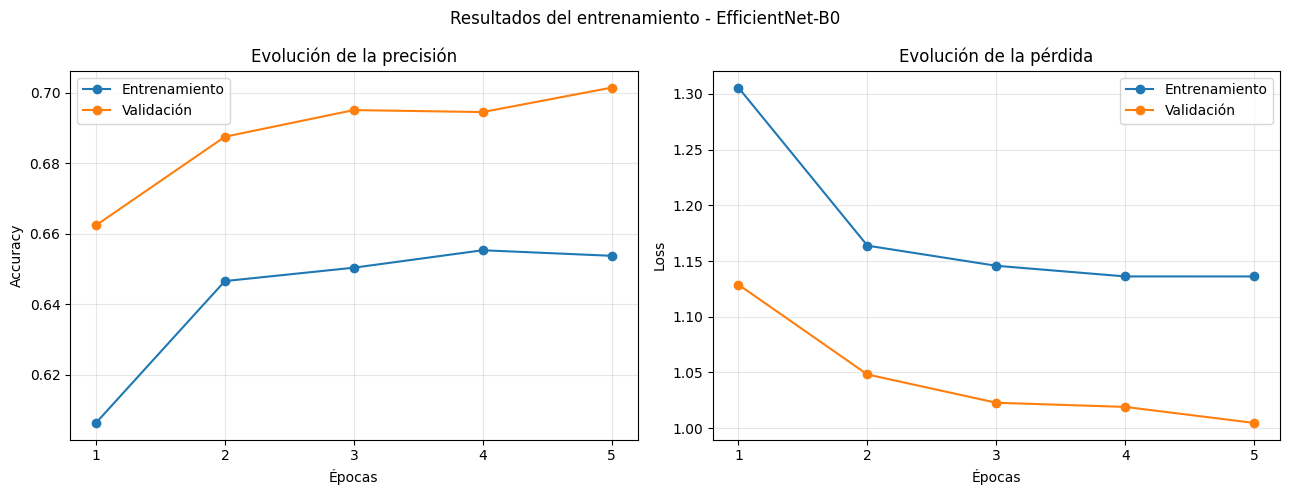

In [16]:
# Obtener resultados del entrenamiento
historial = historial_efficientnet.history
epocas = range(1, len(historial["accuracy"]) + 1)

plt.figure(figsize=(13, 5))

# Gráfico de precisión
plt.subplot(1, 2, 1)
plt.plot(epocas, historial["accuracy"], marker="o", label="Entrenamiento")
plt.plot(epocas, historial["val_accuracy"], marker="o", label="Validación")
plt.title("Evolución de la precisión")
plt.xlabel("Épocas")
plt.ylabel("Accuracy")
plt.xticks(epocas)
plt.legend()
plt.grid(alpha=0.3)

# Gráfico de pérdida
plt.subplot(1, 2, 2)
plt.plot(epocas, historial["loss"], marker="o", label="Entrenamiento")
plt.plot(epocas, historial["val_loss"], marker="o", label="Validación")
plt.title("Evolución de la pérdida")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.xticks(epocas)
plt.legend()
plt.grid(alpha=0.3)

plt.suptitle("Resultados del entrenamiento - EfficientNet-B0")
plt.tight_layout()
plt.show()


Como se puede observar los gráficos, se ve que EfficientNet-B0 fue mejorando durante las cinco épocas de entrenamiento. Su accuracy de validación aumentó desde un 66,24% hasta un 70,14%, mientras que el valor de pérdida disminuyó de 1,1288 a 1,0047. También observamos que, después de las primeras épocas, las mejoras comenzaron a ser más leves, lo cual nos indica que el aprendizaje se fue estabilizando.

También no encontramos señales claras de sobreajuste, ya que la pérdida de validación continuó disminuyendo y no presentó un aumento sostenido. A su vez, algo que nos llamó la atención es que el accuracy de validación fue superior al de entrenamiento, en donde, después de investigar pensamos que puede explicarse, en parte, porque durante el entrenamiento utilizamos Dropout, que desactiva temporalmente algunas conexiones para reducir el sobreajuste.

En general, EfficientNet-B0 mostró una evolución positiva durante las cinco épocas, aunque todavía existe margen para mejorar sus resultados mediante ajustes adicionales.

#### 4.5. Evaluación de EfficientNet-B0 con el conjunto de prueba
**Objetivo:** Se evaluará la calidad en que clasifica EfficientNet-B0 los documentos que no ha visto antes, observando su certeza e identificando las categorías en las que presenta mayores dificultades.

2500/2500 [==============================] - 164s 65ms/step

RESULTADOS DE EFFICIENTNET-B0 - TEST
Imágenes evaluadas: 39,999
Accuracy:  0.7093
Precision: 0.7104
Recall:    0.7085
F1-score:  0.7066
Tiempo de evaluación: 2.8 minutos

RESULTADOS POR CATEGORÍA
                        precision    recall  f1-score   support

                 Carta      0.569     0.681     0.620      2464
            Formulario      0.526     0.595     0.558      2506
    Correo electrónico      0.889     0.912     0.901      2516
            Manuscrito      0.901     0.885     0.893      2532
            Publicidad      0.847     0.841     0.844      2515
    Informe científico      0.473     0.327     0.387      2498
Publicación científica      0.910     0.762     0.829      2571
        Especificación      0.749     0.756     0.753      2472
               Carpeta      0.790     0.961     0.867      2527
               Noticia      0.802     0.772     0.787      2463
           Presupuesto      0.616     

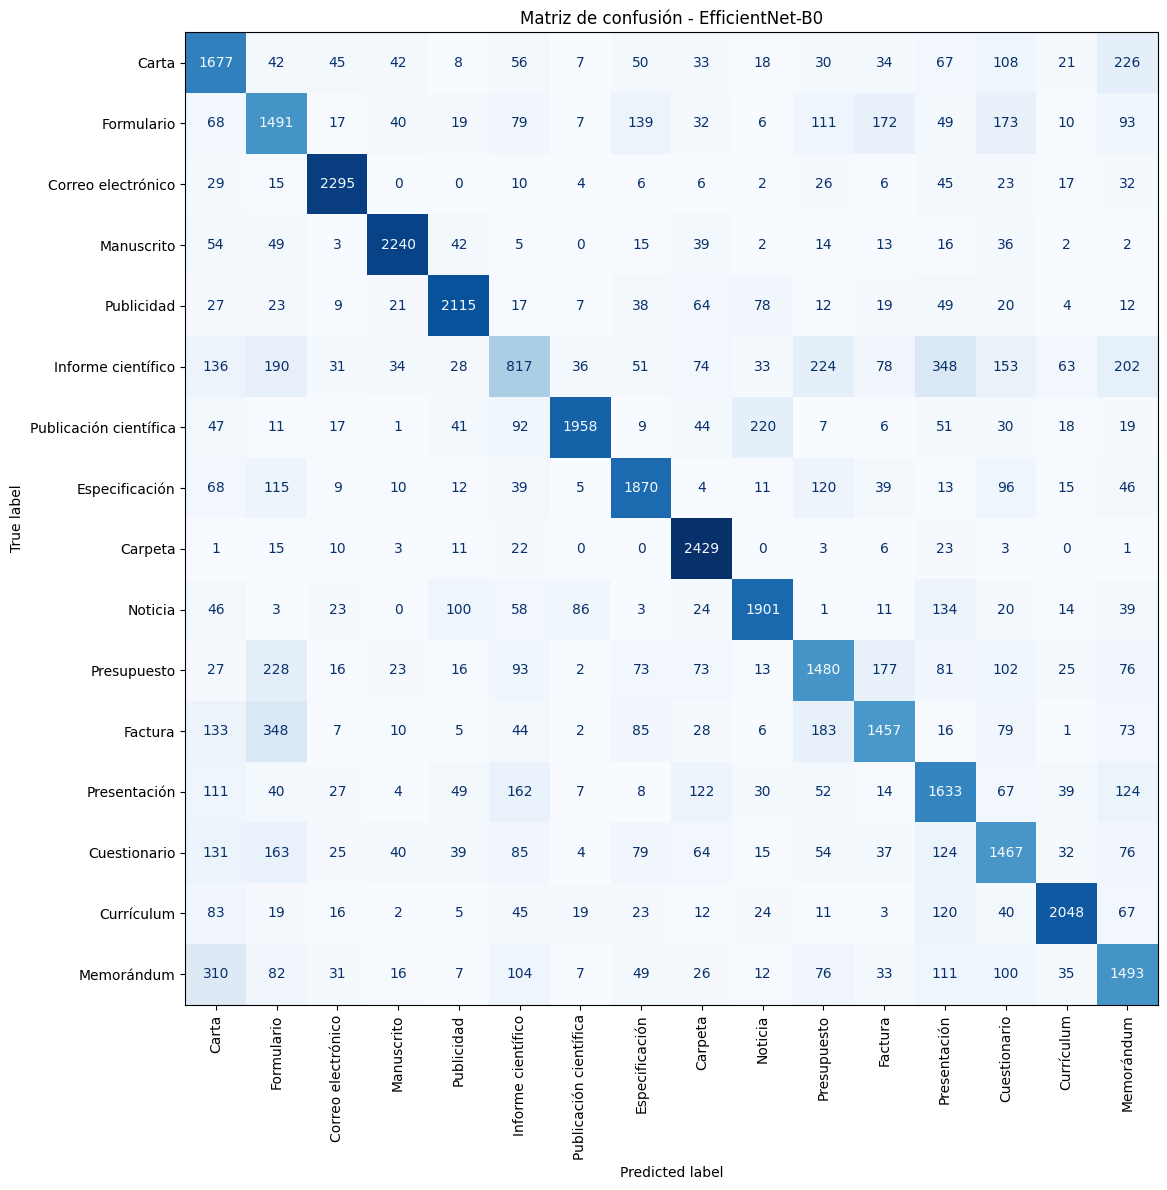

In [17]:
# Crear el conjunto de prueba con las imágenes verificadas
test_ds_validos = crear_dataset(
    X_test_validos,
    y_test_validos,
    entrenamiento=False
)

# Obtener las predicciones del modelo
inicio = time.perf_counter()

probabilidades_efficientnet = modelo_efficientnet.predict(
    test_ds_validos,
    verbose=1
)

tiempo_evaluacion = time.perf_counter() - inicio

# Obtener la clase con mayor probabilidad
y_pred_efficientnet = np.argmax(
    probabilidades_efficientnet,
    axis=1
)

# Calcular las métricas
accuracy_efficientnet = accuracy_score(
    y_test_validos, y_pred_efficientnet
)

precision_efficientnet = precision_score(
    y_test_validos, y_pred_efficientnet,
    average="macro", zero_division=0
)

recall_efficientnet = recall_score(
    y_test_validos, y_pred_efficientnet,
    average="macro", zero_division=0
)

f1_efficientnet = f1_score(
    y_test_validos, y_pred_efficientnet,
    average="macro", zero_division=0
)

# Mostrar resultados generales
print("\nRESULTADOS DE EFFICIENTNET-B0 - TEST")
print("=" * 50)

print(f"Imágenes evaluadas: {len(y_test_validos):,}")
print(f"Accuracy:  {accuracy_efficientnet:.4f}")
print(f"Precision: {precision_efficientnet:.4f}")
print(f"Recall:    {recall_efficientnet:.4f}")
print(f"F1-score:  {f1_efficientnet:.4f}")
print(f"Tiempo de evaluación: {tiempo_evaluacion / 60:.1f} minutos")

# Resultados por categoría
print("\nRESULTADOS POR CATEGORÍA")
print("=" * 50)

print(classification_report(
    y_test_validos,
    y_pred_efficientnet,
    labels=range(NUM_CLASES),
    target_names=CLASES,
    digits=3,
    zero_division=0
))

# Matriz de confusión
matriz_efficientnet = confusion_matrix(
    y_test_validos,
    y_pred_efficientnet,
    labels=range(NUM_CLASES)
)

fig, ax = plt.subplots(figsize=(15, 12))

ConfusionMatrixDisplay(
    confusion_matrix=matriz_efficientnet,
    display_labels=CLASES
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    values_format="d",
    colorbar=False
)

plt.title("Matriz de confusión - EfficientNet-B0")
plt.tight_layout()
plt.show()



Al evaluar EfficientNet-B0 con las 39.999 imágenes de prueba, tuvimos como resultado un 70,93% de accuracy, lo que significa que el modelo fue capaz de clasificar correctamente aproximadamente 71 de cada 100 documentos.

Al revisar los resultados por categoría junto con la matriz de confusión, podemos observar que el modelo reconoce bastante bien las carpetas, los correos electrónicos y los manuscritos, con un recall de 96,1%, 91,2% y 88,5%, respectivamente. Sin embargo, también se presentaron algunas dificultades, especialmente con los informes científicos, donde solo reconoció correctamente el 32,7% de los documentos. Otro ejemplo son las facturas, ya que 348 fueron clasificadas como formularios y 183 como presupuestos.

Esto nos demuestra que, aunque el modelo obtiene resultados generales aceptables, todavía puede confundir documentos que tienen características visuales similares. Por eso, es importante revisar las clasificaciones antes de utilizarlas para organizar información importante.

#### 4.6. Preparación y construcción del modelo ResNet50
**Objetivo:** Se adaptará ResNet50 para que clasifique las mismas 16 categorías de documentos, utilizando los mismos conjuntos de datos que EfficientNet-B0 para comparar los resultados en base a las mismas condiciones.

In [18]:
# Adaptar las imágenes al formato que necesita ResNet50
def preparar_resnet(imagenes, etiquetas):
    imagenes = keras.applications.resnet50.preprocess_input(imagenes)
    return imagenes, etiquetas

# Preparar los conjuntos para ResNet50
train_ds_resnet = train_ds.map(
    preparar_resnet,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

val_ds_resnet = val_ds.map(
    preparar_resnet,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

test_ds_resnet = test_ds_validos.map(
    preparar_resnet,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

# Cargar ResNet50 preentrenado
base_resnet = keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=TAMANO_ENTRADA
)

# Congelar las capas preentrenadas
base_resnet.trainable = False

# Construir el modelo de clasificación
entradas = keras.Input(shape=TAMANO_ENTRADA)

x = base_resnet(entradas, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

salidas = layers.Dense(
    NUM_CLASES,
    activation="softmax"
)(x)

modelo_resnet = keras.Model(
    inputs=entradas,
    outputs=salidas,
    name="DocFlow_ResNet50"
)

# Compilar el modelo
modelo_resnet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Mostrar la arquitectura
modelo_resnet.summary()

print("\nModelo ResNet50 construido correctamente.")
print("Número de clases:", NUM_CLASES)
print("Capas preentrenadas congeladas:", not base_resnet.trainable)

Model: "DocFlow_ResNet50"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_4 (InputLayer)        [(None, 384, 384, 3)]     0         
                                                                 
 resnet50 (Functional)       (None, 12, 12, 2048)      23587712  
                                                                 
 global_average_pooling2d_1   (None, 2048)             0         
 (GlobalAveragePooling2D)                                        
                                                                 
 dropout_1 (Dropout)         (None, 2048)              0         
                                                                 
 dense_1 (Dense)             (None, 16)                32784     
                                                                 
Total params: 23,620,496
Trainable params: 32,784
Non-trainable params: 23,587,712
_________________________________

#### 4.7. Entrenamiento del modelo ResNet50
**Objetivo:** Se entrenará el modelo ResNet50 con las imágenes del dataset RVL-CDIP, utilizando los mismos criterios que EfficientNet-B0 para así posteriormente poder comparar cuál reconoce mejor las distintas categorías de documentos.

In [19]:
# Configuración del entrenamiento
EPOCAS_RESNET = 5

# Carpeta para guardar los resultados
ruta_modelos = ruta_datos.parent / "modelos"
ruta_modelos.mkdir(parents=True, exist_ok=True)

# Configurar callbacks
callbacks_resnet = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath=str(ruta_modelos / "resnet50_mejor.h5"),
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    keras.callbacks.CSVLogger(
        str(ruta_modelos / "historial_resnet50.csv")
    )
]

# Entrenar el modelo
inicio = time.perf_counter()

historial_resnet = modelo_resnet.fit(
    train_ds_resnet,
    validation_data=val_ds_resnet,
    epochs=EPOCAS_RESNET,
    callbacks=callbacks_resnet,
    verbose=1
)

tiempo_entrenamiento_resnet = time.perf_counter() - inicio

# Mostrar resultados
print("\nENTRENAMIENTO RESNET50 FINALIZADO")
print("=" * 50)

print(f"Épocas realizadas: {len(historial_resnet.history['loss'])}")
print(f"Tiempo total: {tiempo_entrenamiento_resnet / 60:.1f} minutos")
print(f"Mejor accuracy de validación: {max(historial_resnet.history['val_accuracy']):.4f}")
print(f"Menor loss de validación: {min(historial_resnet.history['val_loss']):.4f}")

print("\nMejores pesos guardados en:", ruta_modelos)


Epoch 1/5
8000/8000 [==============================] - ETA: 0s - loss: 1.3618 - accuracy: 0.5914
Epoch 1: val_loss improved from inf to 1.16472, saving model to C:\Users\benja\Documents\IA Generativa\Talleres\Certamen 1\modelos\resnet50_mejor.h5
8000/8000 [==============================] - 1059s 132ms/step - loss: 1.3618 - accuracy: 0.5914 - val_loss: 1.1647 - val_accuracy: 0.6487
Epoch 2/5
8000/8000 [==============================] - ETA: 0s - loss: 1.2382 - accuracy: 0.6319
Epoch 2: val_loss improved from 1.16472 to 1.10671, saving model to C:\Users\benja\Documents\IA Generativa\Talleres\Certamen 1\modelos\resnet50_mejor.h5
8000/8000 [==============================] - 1056s 132ms/step - loss: 1.2382 - accuracy: 0.6319 - val_loss: 1.1067 - val_accuracy: 0.6701
Epoch 3/5
8000/8000 [==============================] - ETA: 0s - loss: 1.2196 - accuracy: 0.6399
Epoch 3: val_loss improved from 1.10671 to 1.05204, saving model to C:\Users\benja\Documents\IA Generativa\Talleres\Certamen 1\mode

#### 4.8. Análisis del entrenamiento de ResNet50
**Objetivo:** Se analizará cómo cambió la precisión y el error de ResNet50 en el transcurso de las 5 épocas, comprobando así su mejoría y en qué momento obtuvo sus mejores resultados.

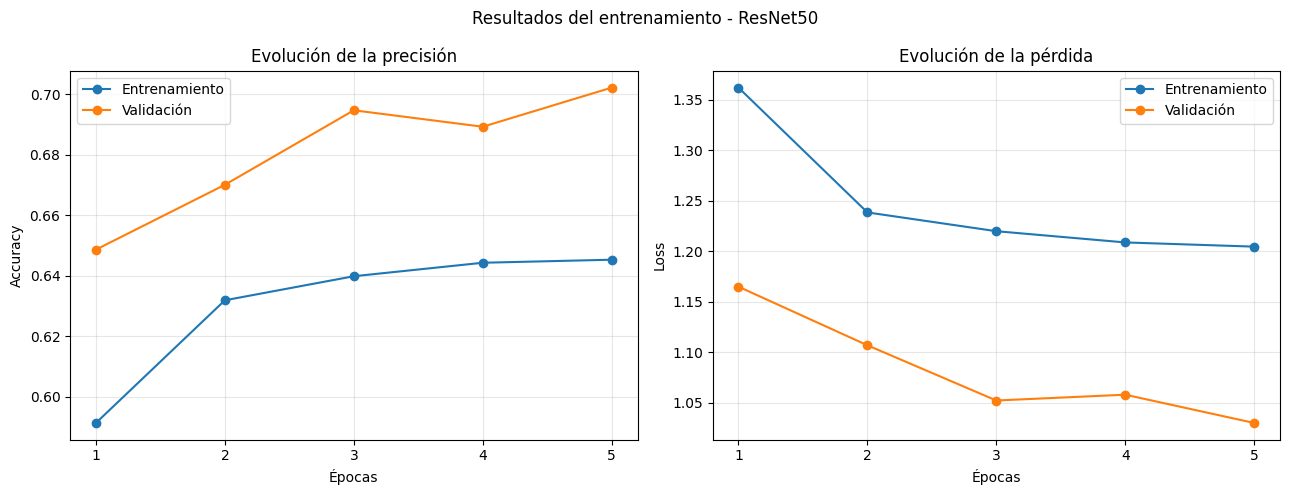

In [20]:
# Obtener los resultados del entrenamiento
historial = historial_resnet.history
epocas = range(1, len(historial["accuracy"]) + 1)

plt.figure(figsize=(13, 5))

# Gráfico de precisión
plt.subplot(1, 2, 1)
plt.plot(epocas, historial["accuracy"], marker="o", label="Entrenamiento")
plt.plot(epocas, historial["val_accuracy"], marker="o", label="Validación")
plt.title("Evolución de la precisión")
plt.xlabel("Épocas")
plt.ylabel("Accuracy")
plt.xticks(epocas)
plt.legend()
plt.grid(alpha=0.3)

# Gráfico de pérdida
plt.subplot(1, 2, 2)
plt.plot(epocas, historial["loss"], marker="o", label="Entrenamiento")
plt.plot(epocas, historial["val_loss"], marker="o", label="Validación")
plt.title("Evolución de la pérdida")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.xticks(epocas)
plt.legend()
plt.grid(alpha=0.3)

plt.suptitle("Resultados del entrenamiento - ResNet50")
plt.tight_layout()
plt.show()


Al observar los gráficos, podemos ver que ResNet50 fue mejorando durante las cinco épocas de entrenamiento. Su accuracy de validación aumentó desde un 64,87% hasta un 70,23%, mientras que la pérdida disminuyó de 1,1647 a 1,0298. Sin embargo, en la cuarta época observamos que existe una pequeña disminución del accuracy de validación y un aumento de la pérdida. A pesar de esto, el modelo volvió a mejorar en la quinta época, donde obtuvo sus mejores resultados.

Por otra parte, no encontramos señales claras de sobreajuste durante las cinco épocas, ya que la pérdida de validación terminó disminuyendo y el modelo continuó mejorando. También observamos que el accuracy de validación fue superior al de entrenamiento, lo que puede explicarse, en parte, por el uso de Dropout durante el entrenamiento al igual que en el modelo anterior

En general, ResNet50 mostró una evolución positiva, aunque presentó una pequeña fluctuación durante el proceso y todavía tiene margen para mejorar sus resultados.

#### 4.9. Evaluación de ResNet50 con el conjunto de prueba
**Objetivo:** Se evaluará cómo clasifica ResNet50 los documentos que no fueron utilizados durante el entrenamiento, identificando así sus resultados generales y las categorías en las que presenta menos precisión.

2500/2500 [==============================] - 262s 105ms/step

RESULTADOS DE RESNET50 - TEST
Imágenes evaluadas: 39,999
Accuracy:  0.7014
Precision: 0.7065
Recall:    0.7003
F1-score:  0.7002
Tiempo de evaluación: 4.4 minutos

RESULTADOS POR CATEGORÍA
                        precision    recall  f1-score   support

                 Carta      0.601     0.586     0.593      2464
            Formulario      0.569     0.543     0.556      2506
    Correo electrónico      0.947     0.870     0.907      2516
            Manuscrito      0.896     0.883     0.889      2532
            Publicidad      0.859     0.819     0.839      2515
    Informe científico      0.458     0.414     0.435      2498
Publicación científica      0.768     0.856     0.810      2571
        Especificación      0.731     0.784     0.757      2472
               Carpeta      0.860     0.925     0.891      2527
               Noticia      0.872     0.691     0.771      2463
           Presupuesto      0.661     0.567 

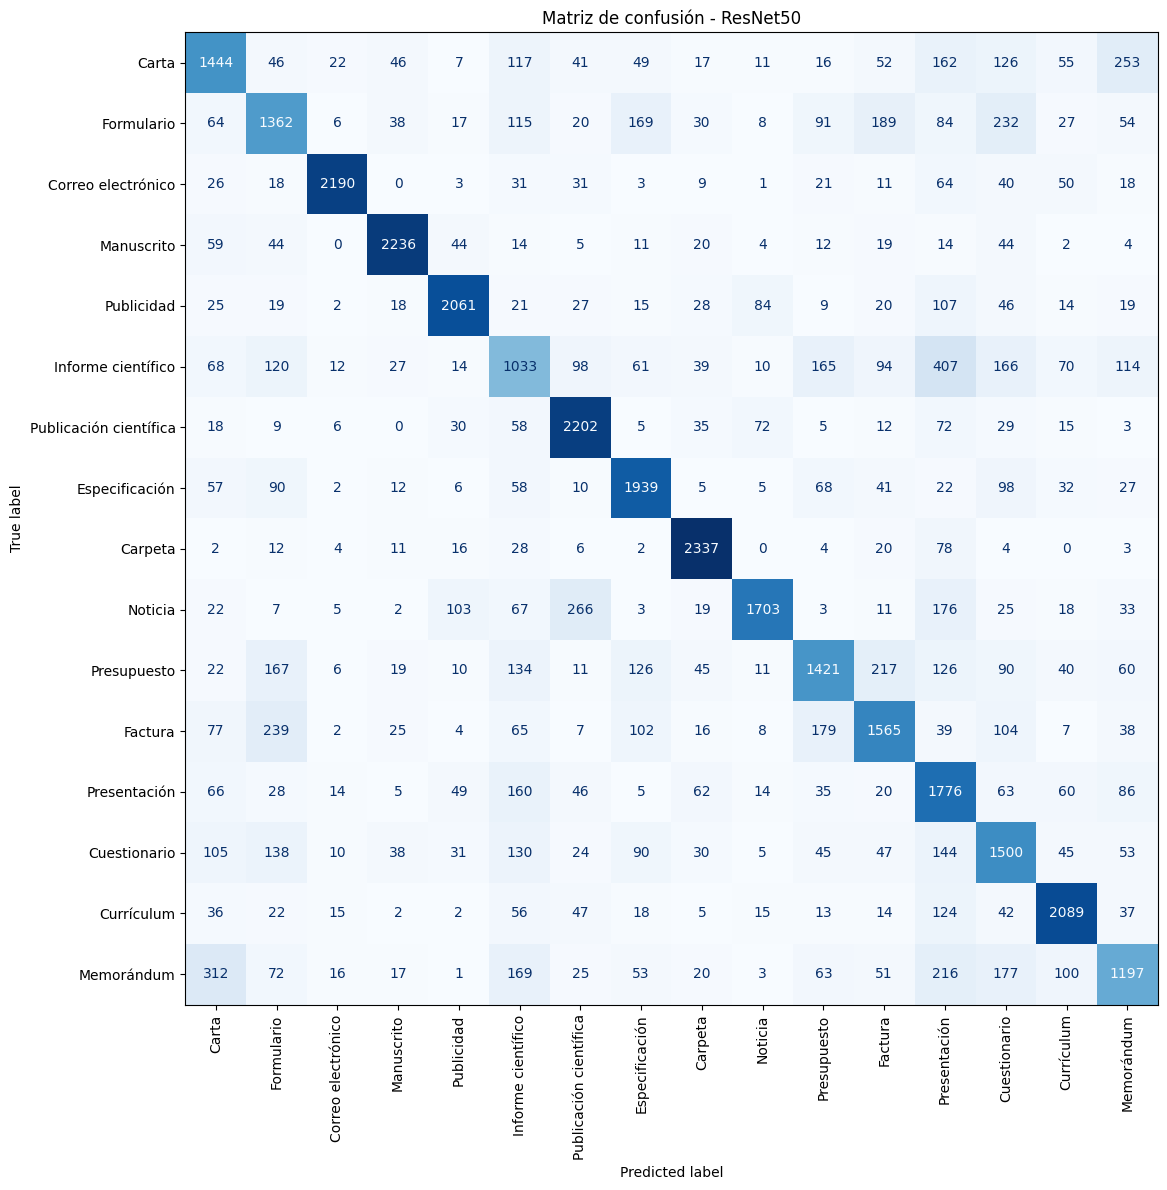

In [21]:
# Obtener las predicciones del modelo
inicio = time.perf_counter()

probabilidades_resnet = modelo_resnet.predict(
    test_ds_resnet,
    verbose=1
)

tiempo_evaluacion_resnet = time.perf_counter() - inicio

# Obtener la clase con mayor probabilidad
y_pred_resnet = np.argmax(probabilidades_resnet, axis=1)

# Calcular las métricas
accuracy_resnet = accuracy_score(
    y_test_validos, y_pred_resnet
)

precision_resnet = precision_score(
    y_test_validos, y_pred_resnet,
    average="macro", zero_division=0
)

recall_resnet = recall_score(
    y_test_validos, y_pred_resnet,
    average="macro", zero_division=0
)

f1_resnet = f1_score(
    y_test_validos, y_pred_resnet,
    average="macro", zero_division=0
)

# Mostrar resultados generales
print("\nRESULTADOS DE RESNET50 - TEST")
print("=" * 50)

print(f"Imágenes evaluadas: {len(y_test_validos):,}")
print(f"Accuracy:  {accuracy_resnet:.4f}")
print(f"Precision: {precision_resnet:.4f}")
print(f"Recall:    {recall_resnet:.4f}")
print(f"F1-score:  {f1_resnet:.4f}")
print(f"Tiempo de evaluación: {tiempo_evaluacion_resnet / 60:.1f} minutos")

# Resultados por categoría
print("\nRESULTADOS POR CATEGORÍA")
print("=" * 50)

print(classification_report(
    y_test_validos,
    y_pred_resnet,
    labels=range(NUM_CLASES),
    target_names=CLASES,
    digits=3,
    zero_division=0
))

# Matriz de confusión
matriz_resnet = confusion_matrix(
    y_test_validos,
    y_pred_resnet,
    labels=range(NUM_CLASES)
)

fig, ax = plt.subplots(figsize=(15, 12))

ConfusionMatrixDisplay(
    confusion_matrix=matriz_resnet,
    display_labels=CLASES
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    values_format="d",
    colorbar=False
)

plt.title("Matriz de confusión - ResNet50")
plt.tight_layout()
plt.show()


Al evaluar ResNet50 con las 39.999 imágenes de prueba, se obtuvo un 70,14% de accuracy, lo que significa el modelo fue capaz de clasificar correctamente aproximadamente 70 de cada 100 documentos.

Al revisar los resultados por categoría junto con la matriz de confusión, observamos que el modelo reconoce bastante bien las carpetas, los manuscritos y los correos electrónicos, con un recall de 92,5%, 88,3% y 87,0%, respectivamente. Sin embargo, también presentó dificultades para identificar ciertos documentos, especialmente los informes científicos y memorándums, donde reconoció correctamente el 41,4% y 48,0% de las imágenes. A partir de esto se puede decir que todavía confunde algunas categorías con características visuales similares.

Por otra parte, ResNet50 logró reconocer el 63,2% de las facturas reales, superando a EfficientNet-B0 en esta categoría. Esto nos da a conocer que, aunque ambos modelos obtuvieron resultados generales parecidos, cada uno presenta fortalezas y debilidades diferentes según el tipo de documento.

#### 4.10. Comparación de EfficientNet-B0 y ResNet50
**Objetivo:** Se compararán los resultados obtenidos de EfficientNet-B0 y ResNet50, utilizando las mismas 39999 imágenes de prueba, teniendo en consideración la calidad de sus clasificaciones junto con el tiempo necesario para entrenarlos.

COMPARACIÓN DE LOS 2 MODELOS


,Modelo,Accuracy,Precision,Recall,F1-score,Tiempo entrenamiento (min),Tiempo evaluación (min)
0,EfficientNet-B0,70.93,71.04,70.85,70.66,60.20,2.76
1,ResNet50,70.14,70.65,70.03,70.02,87.97,4.38


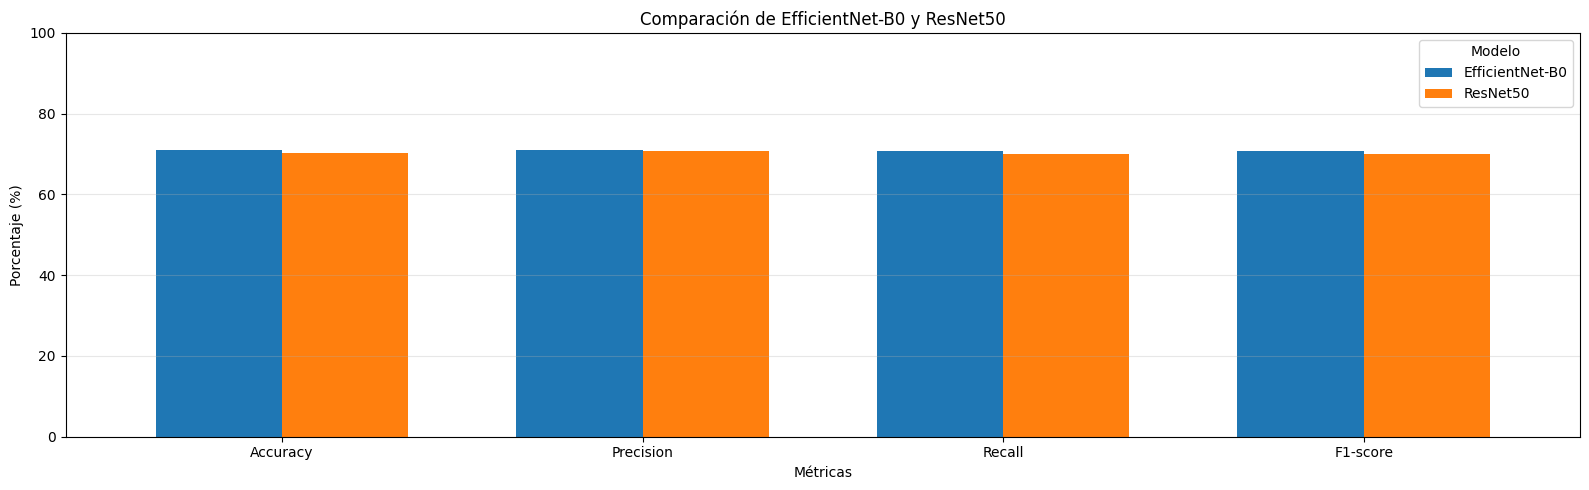

In [27]:
# Reunir los resultados de ambos modelos
comparacion_modelos = pd.DataFrame({
    "Modelo": ["EfficientNet-B0", "ResNet50"],
    "Accuracy": [accuracy_efficientnet, accuracy_resnet],
    "Precision": [precision_efficientnet, precision_resnet],
    "Recall": [recall_efficientnet, recall_resnet],
    "F1-score": [f1_efficientnet, f1_resnet],
    "Tiempo entrenamiento (min)": [
        tiempo_entrenamiento / 60,
        tiempo_entrenamiento_resnet / 60
    ],
    "Tiempo evaluación (min)": [
        tiempo_evaluacion / 60,
        tiempo_evaluacion_resnet / 60
    ]
})

# Mostrar tabla comparativa en porcentajes
tabla_comparacion = comparacion_modelos.copy()

metricas = ["Accuracy", "Precision", "Recall", "F1-score"]
tabla_comparacion[metricas] = tabla_comparacion[metricas] * 100

print("COMPARACIÓN DE LOS 2 MODELOS")
display(tabla_comparacion.round(2))

# Gráfico comparativo de métricas
datos_grafico = tabla_comparacion.set_index("Modelo")[metricas].T

ax = datos_grafico.plot(
    kind="bar",
    figsize=(16, 5),
    width=0.7
)

plt.title("Comparación de EfficientNet-B0 y ResNet50")
plt.xlabel("Métricas")
plt.ylabel("Porcentaje (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Modelo")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Al analizar ambos modelos, nos encontramos con que EfficientNet-B0 obtuvo resultados ligeramente mejores, alcanzando un accuracy del 70,93% en comparación al 70,14% de ResNet50. Además, se necesitó menos tiempo tanto para la parte de entrenamiento como para evaluar las imágenes de prueba. También, aunque en ambos modelos se evidenciaron dificultades con algunas categorías de documentos, consideramos que EfficientNet-B0 es la alternativa más conveniente para este proyecto, debido a que nos ofrece un rendimiento similar o levemente superior utilizando menos recursos.

##### 4.10.1. Análisis de errores de clasificación y sus consecuencias

Como pudimos observar anteriormente, aunque EfficientNet-B0 obtuvo mejores resultados generales, también hay que tener en cuenta qué documentos clasifica incorrectamente y qué consecuencias podrían tener esos errores.
Un claro ejemplo sería un error en donde no se reconozca una factura correctamente, lo cual podría generar problemas al organizar documentos financieros, retrasar su revisión o dificultar su búsqueda.

En nuestros resultados, EfficientNet-B0 reconoció correctamente el 58,8% de las facturas reales, mientras que ResNet50 alcanzó un 63,2%. Lo cual nos dice que ResNet50 tuvo un mejor desempeño al momento de detectar este tipo de documentos. Sin embargo, EfficientNet-B0 obtuvo una mayor precisión en las predicciones de facturas (un 69,2% frente a 65,7%), por lo que una mayor proporción de los documentos que identificó como facturas realmente pertenecían a esa categoría. Además, al revisar la matriz de confusión de EfficientNet-B0, observamos que 348 facturas fueron clasificadas como formularios y 183 como presupuestos, lo cual  demuestra que el modelo puede confundir documentos que tienen una estructura visual parecida.

Por otra parte, los informes científicos fueron una de las categorías más difíciles de reconocer, con un recall de 32,7%. Sin embargo, que una categoría tenga muchos errores no necesariamente es aquella cuyos errores tienen las consecuencias más importantes.

Finalmente, mantuvimos EfficientNet-B0 como modelo principal porque obtuvo mejores resultados generales (un 70,93% de accuracy frente a un 70,14% de ResNet50) y necesitó menos tiempo de entrenamiento y evaluación. 

Estos resultados nos permiten concluir que DocFlow AI debe funcionar como una herramienta de apoyo, manteniendo la revisión humana, especialmente cuando se trata de documentos importantes.

##### 4.10.2. Limitaciones del dataset y su influencia en los resultados
Además de las limitaciones que identificamos anteriormente, encontramos un estudio publicado por Larson y colaboradores (2026), donde se analizaron problemas de calidad en RVL-CDIP.

En este estudio, los investigadores encontraron que aproximadamente el 12% de los documentos presenta errores en sus etiquetas, lo que quiere decir que algunas imágenes están clasificadas en categorías que no les corresponden. También identificaron que cerca del 35% del conjunto de prueba original contiene documentos duplicados o muy parecidos a otros del conjunto de entrenamiento. Lo cual es bastante importante, debido a que los errores en las etiquetas pueden dificultar el aprendizaje de los modelos, mientras que los documentos repetidos pueden hacer que los resultados de evaluación parezcan mejores de lo que realmente serían con documentos completamente nuevos.

En el presente proyecto se utilizó una muestra estratificada del 40% para entrenamiento y validación, pero no realizamos una revisión específica de etiquetas incorrectas ni de documentos duplicados. Por lo tanto, no podemos asegurar que esos porcentajes se repitan exactamente en nuestra muestra.

Esta es una limitación que debemos considerar al interpretar el 70,93% de accuracy obtenido por EfficientNet-B0.

**Referencia:** Larson et al. (2026). *Revising RVL-CDIP: Quantifying Errors and Test-Train Overlap*. https://arxiv.org/abs/2606.31446

#### 4.11. Exportación del modelo seleccionado
**Objetivo:** Se guardará EfficientNet-B0 con sus mejores pesos para posteriormente utilizarlo en la aplicación web de DocFlow AI.

In [29]:
# Guardar el modelo seleccionado para DocFlow AI

# Recuperar los mejores pesos
ruta_pesos = ruta_modelos / "efficientnet_b0_mejor.h5"
modelo_efficientnet.load_weights(str(ruta_pesos))

# Definir la entrada y salida para la aplicación
@tf.function(input_signature=[
    tf.TensorSpec(
        shape=(None,) + TAMANO_ENTRADA,
        dtype=tf.float32,
        name="imagenes"
    )
])
def clasificar(imagenes):
    return {
        "probabilidades": modelo_efficientnet(imagenes, training=False)
    }

# Exportar el modelo completo en formato SavedModel
ruta_modelo_final = ruta_modelos / "docflow_efficientnet_b0"

tf.saved_model.save(
    modelo_efficientnet,
    str(ruta_modelo_final),
    signatures={"serving_default": clasificar}
)

print("MODELO EXPORTADO CORRECTAMENTE")
print("=" * 45)
print("Modelo seleccionado: EfficientNet-B0")
print(f"Accuracy en prueba: {accuracy_efficientnet:.2%}")
print("Modelo guardado en:", ruta_modelo_final)


MODELO EXPORTADO CORRECTAMENTE
Modelo seleccionado: EfficientNet-B0
Accuracy en prueba: 70.93%
Modelo guardado en: C:\Users\benja\Documents\IA Generativa\Talleres\Certamen 1\modelos\docflow_efficientnet_b0


### 5. Desarrollo de la aplicación web

#### 5.1. Preparación de la aplicación web
**Objetivo:** Se preparará la carpeta en donde desarrollaremos DocFlow AI. A su vez copiaremos el modelo entrenado para utilizarlo en la aplicación sin tener que entrenarlo nuevamente.

In [31]:
import shutil

# Crear la carpeta de DocFlow AI
ruta_app = ruta_datos.parent / "DocFlow-AI"
ruta_app.mkdir(parents=True, exist_ok=True)

# Copiar el modelo entrenado a la aplicación
ruta_modelo_app = ruta_app / "modelo" / "docflow_efficientnet_b0"

shutil.copytree(
    ruta_modelo_final,
    ruta_modelo_app,
    dirs_exist_ok=True
)

# Verificar que el modelo se copió correctamente
assert (ruta_modelo_app / "saved_model.pb").is_file()
assert (ruta_modelo_app / "variables").is_dir()

print("APLICACIÓN PREPARADA CORRECTAMENTE")
print("=" * 45)
print("Carpeta del proyecto:", ruta_app)
print("Modelo disponible:", ruta_modelo_app)


APLICACIÓN PREPARADA CORRECTAMENTE
Carpeta del proyecto: C:\Users\benja\Documents\IA Generativa\Talleres\Certamen 1\DocFlow-AI
Modelo disponible: C:\Users\benja\Documents\IA Generativa\Talleres\Certamen 1\DocFlow-AI\modelo\docflow_efficientnet_b0


#### 5.2. Desarrollo de la interfaz de DocFlow AI 
**Objetivo:** En este paso se creará la aplicación web interactiva, la cual será capaz de clasificar documentos, visualizar los resultados de EfficientNet-B0 y consultar el rendimiento del modelo.

In [ ]:
codigo_app = r'''
from pathlib import Path
from html import escape
import os

# Compatibilidad del modelo entrenado con TensorFlow 2.10
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import altair as alt
import numpy as np
import pandas as pd
import streamlit as st
import tensorflow as tf
import requests

from PIL import Image, ImageOps



# =============================================================================
# 1. CONFIGURACIÓN DE LA APLICACIÓN
# =============================================================================

st.set_page_config(
    page_title="DocFlow AI | Document Intelligence",
    page_icon="📄",
    layout="wide",
    initial_sidebar_state="expanded"
)

CLASES = [
    "Carta", "Formulario", "Correo electrónico", "Manuscrito",
    "Publicidad", "Informe científico", "Publicación científica",
    "Especificación", "Carpeta", "Noticia", "Presupuesto",
    "Factura", "Presentación", "Cuestionario", "Currículum",
    "Memorándum"
]

TAMANO_IMG = (384, 384)
UMBRAL_CONFIANZA = 0.60

RESULTADOS = pd.DataFrame({
    "Modelo": ["EfficientNet-B0", "ResNet50"],
    "Accuracy": [70.93, 70.14],
    "Precision": [71.04, 70.65],
    "Recall": [70.85, 70.03],
    "F1-score": [70.66, 70.02],
    "Entrenamiento (min)": [60.20, 87.97],
    "Evaluación (min)": [2.76, 4.38]
})


# =============================================================================
# 2. DISEÑO VISUAL
# =============================================================================

st.markdown("""
<style>
@import url('https://fonts.googleapis.com/css2?family=DM+Sans:wght@400;500;600;700;800&display=swap');

html, body, [class*="css"] {
    font-family: 'DM Sans', sans-serif;
}

.stApp {
    background:
        radial-gradient(ellipse at 85% 0%, rgba(30, 200, 210, 0.10), transparent 32%),
        radial-gradient(ellipse at 5% 45%, rgba(123, 92, 240, 0.08), transparent 38%),
        #081321;
}

section[data-testid="stSidebar"] {
    background: #0D1B2C;
    border-right: 1px solid #24364A;
}

.block-container {
    padding-top: 2rem;
    padding-bottom: 3rem;
    max-width: 1450px;
}

.hero {
    background: linear-gradient(115deg, #132D44 0%, #102438 53%, #16243F 100%);
    border: 1px solid #29455A;
    border-radius: 22px;
    padding: 35px 40px;
    margin-bottom: 26px;
    position: relative;
    overflow: hidden;
}

.hero::after {
    content: "";
    position: absolute;
    width: 260px;
    height: 260px;
    border-radius: 50%;
    background: rgba(20, 220, 205, 0.12);
    filter: blur(65px);
    right: -60px;
    top: -120px;
}

.hero-kicker {
    font-size: 0.76rem;
    letter-spacing: 2.2px;
    text-transform: uppercase;
    color: #4DE2D1;
    font-weight: 800;
    margin-bottom: 12px;
}

.hero-title {
    font-size: clamp(2.4rem, 5vw, 4rem);
    font-weight: 800;
    line-height: 1.1;
    color: #F4F8FF;
    letter-spacing: -1.8px;
}

.hero-title span {
    color: #4DE2D1;
}

.hero-description {
    color: #B5C6D9;
    font-size: 1.02rem;
    max-width: 750px;
    line-height: 1.7;
    margin-top: 14px;
}

.section-label {
    color: #4DE2D1;
    font-size: 0.74rem;
    font-weight: 800;
    letter-spacing: 1.8px;
    text-transform: uppercase;
    margin: 20px 0 7px;
}

.section-heading {
    color: #F3F7FD;
    font-size: 1.55rem;
    font-weight: 800;
    margin-bottom: 18px;
}

.metric-card {
    background: linear-gradient(145deg, #14293D, #102033);
    border: 1px solid #2A4255;
    border-radius: 16px;
    padding: 22px;
    margin-bottom: 13px;
    min-height: 122px;
}

.metric-card.accent {
    border-color: rgba(77, 226, 209, 0.55);
    background: linear-gradient(145deg, #123C44, #102B3A);
}

.metric-label {
    color: #A6BDD0;
    font-size: 0.84rem;
    font-weight: 600;
    margin-bottom: 12px;
}

.metric-value {
    color: #F5FAFF;
    font-size: clamp(1.25rem, 2.2vw, 1.95rem);
    line-height: 1.2;
    font-weight: 800;
    overflow-wrap: anywhere;
}

.metric-note {
    color: #94AFC3;
    font-size: 0.77rem;
    margin-top: 10px;
}

.info-panel {
    background: #102438;
    border: 1px solid #284053;
    border-radius: 15px;
    padding: 20px 23px;
    color: #B9CADB;
    line-height: 1.7;
    margin: 12px 0 22px;
}

.sidebar-brand {
    font-size: 1.7rem;
    font-weight: 800;
    color: #F4F8FF;
    letter-spacing: -0.8px;
}

.sidebar-brand span {
    color: #4DE2D1;
}

.sidebar-caption {
    color: #95B2C7;
    font-size: 0.77rem;
    letter-spacing: 1.2px;
    margin-top: 6px;
}

.sidebar-divider {
    height: 1px;
    background: #2B4052;
    margin: 24px 0;
}

.stTabs [data-baseweb="tab-list"] {
    gap: 20px;
    border-bottom: 1px solid #294154;
}

.stTabs [data-baseweb="tab"] {
    font-weight: 700;
    padding: 12px 5px;
}

.stTabs [aria-selected="true"] {
    color: #4DE2D1 !important;
}

div[data-testid="stFileUploader"] section {
    border-radius: 15px;
    border: 1px dashed #52829A;
    background: #102338;
}

div[data-testid="stMetric"] {
    background: #13283A;
    border: 1px solid #2B4457;
    padding: 17px 20px;
    border-radius: 15px;
}

div[data-testid="stDataFrame"] {
    border-radius: 12px;
    overflow: hidden;
}

.footer {
    color: #819AAF;
    font-size: 0.8rem;
    border-top: 1px solid #243B4F;
    margin-top: 40px;
    padding-top: 18px;
}
</style>
""", unsafe_allow_html=True)


# =============================================================================
# 3. FUNCIONES
# =============================================================================

@st.cache_resource
def cargar_modelo():
    ruta = (
        Path(__file__).parent
        / "modelo"
        / "docflow_efficientnet_b0"
    )

    modelo = tf.saved_model.load(str(ruta))
    return modelo.signatures["serving_default"]


def preparar_imagen_web(imagen):
    imagen = imagen.convert("RGB")

    imagen = ImageOps.pad(
        imagen,
        TAMANO_IMG,
        method=Image.Resampling.LANCZOS,
        color=(255, 255, 255)
    )

    arreglo = np.asarray(imagen, dtype=np.float32)
    return np.expand_dims(arreglo, axis=0)


def clasificar_documento(imagen):
    entrada = preparar_imagen_web(imagen)
    predecir = cargar_modelo()

    resultado = predecir(
        imagenes=tf.constant(entrada, dtype=tf.float32)
    )

    probabilidades = resultado["probabilidades"].numpy()[0]

    indice = int(np.argmax(probabilidades))
    categoria = CLASES[indice]
    confianza = float(probabilidades[indice])

    return categoria, confianza, probabilidades

# Generar recomendaciones mediante Gemini
def generar_recomendacion_gemini(categoria, confianza):

    prompt = f"""
    Eres un asistente especializado en gestión documental.

    Un modelo de visión artificial clasificó un documento
    con los siguientes resultados:

    Categoría: {categoria}
    Confianza: {confianza:.2%}

    Entrega una recomendación profesional, breve y clara
    para organizar y gestionar este tipo de documento.

    Consideraciones:
    - Propón tres acciones concretas para el usuario.
    - Si la confianza es menor al 60%, recomienda revisión manual.
    - No inventes información específica del documento.
    - No afirmes haber visto o leído la imagen original.
    - Utiliza un lenguaje natural y fácil de comprender.
    - Responde en español.
    """

    respuesta = requests.post(
        "https://generativelanguage.googleapis.com/v1beta/models/gemini-3.5-flash-lite:generateContent",
        headers={
            "x-goog-api-key": st.secrets["GEMINI_API_KEY"],
            "Content-Type": "application/json"
        },
        json={
            "contents": [
                {"parts": [{"text": prompt}]}
            ],
            "generationConfig": {
                "temperature": 0.3,
                "maxOutputTokens": 1000
            }
        },
        timeout=45
    )

    respuesta.raise_for_status()

    datos = respuesta.json()
    candidatos = datos.get("candidates", [])

    if not candidatos:
        raise ValueError("Gemini no devolvió una recomendación.")

    partes = candidatos[0].get("content", {}).get("parts", [])

    recomendacion = "".join(
        parte.get("text", "")
        for parte in partes
    ).strip()

    if not recomendacion:
        raise ValueError("Gemini devolvió una respuesta vacía.")

    return recomendacion

def tarjeta(titulo, valor, detalle="", destacada=False):
    clase = "metric-card accent" if destacada else "metric-card"

    st.markdown(
        f"""
        <div class="{clase}">
            <div class="metric-label">{escape(str(titulo))}</div>
            <div class="metric-value">{escape(str(valor))}</div>
            <div class="metric-note">{escape(str(detalle))}</div>
        </div>
        """,
        unsafe_allow_html=True
    )


def grafico_probabilidades(probabilidades, categoria_predicha):
    datos = pd.DataFrame({
        "categoria": CLASES,
        "probabilidad": probabilidades.astype(float)
    })

    grafico = (
        alt.Chart(datos)
        .mark_bar(cornerRadiusEnd=5, size=17)
        .encode(
            x=alt.X(
                "probabilidad:Q",
                scale=alt.Scale(domain=[0, 1]),
                axis=alt.Axis(format=".0%", title="Probabilidad")
            ),
            y=alt.Y(
                "categoria:N",
                sort=alt.SortField(
                    field="probabilidad",
                    order="descending"
                ),
                title=None
            ),
            color=alt.condition(
                alt.datum.categoria == categoria_predicha,
                alt.value("#4DE2D1"),
                alt.value("#526E8A")
            ),
            tooltip=[
                alt.Tooltip("categoria:N", title="Categoría"),
                alt.Tooltip(
                    "probabilidad:Q",
                    title="Probabilidad",
                    format=".2%"
                )
            ]
        )
        .properties(
            height=520,
            background="#102438"
        )
        .configure_view(strokeWidth=0)
        .configure_axis(
            labelColor="#B9CADB",
            titleColor="#B9CADB",
            gridColor="#264055",
            labelFontSize=12
        )
    )

    return grafico


# =============================================================================
# 4. BARRA LATERAL
# =============================================================================

st.sidebar.markdown(
    '<div class="sidebar-brand">DOCFLOW<span>AI</span></div>',
    unsafe_allow_html=True
)

st.sidebar.markdown(
    '<div class="sidebar-caption">DOCUMENT INTELLIGENCE PLATFORM</div>',
    unsafe_allow_html=True
)

st.sidebar.markdown(
    '<div class="sidebar-divider"></div>',
    unsafe_allow_html=True
)

st.sidebar.markdown("**Modelo de clasificación**")
st.sidebar.write("EfficientNet-B0")

st.sidebar.markdown("**Documentos reconocidos**")
st.sidebar.write("16 categorías")

st.sidebar.markdown("**Conjunto de prueba**")
st.sidebar.write("39.999 imágenes")

st.sidebar.markdown(
    '<div class="sidebar-divider"></div>',
    unsafe_allow_html=True
)

st.sidebar.metric("Accuracy en prueba", "70,93%")

st.sidebar.info(
    "Prototipo académico. Las clasificaciones son orientativas "
    "y deben revisarse antes de tomar decisiones importantes."
)


# =============================================================================
# 5. ENCABEZADO
# =============================================================================

st.markdown(
    """
    <div class="hero">
        <div class="hero-kicker">Document intelligence · Prototype</div>
        <div class="hero-title">DocFlow <span>AI</span></div>
        <div class="hero-description">
            Clasificación inteligente de documentos mediante visión
            por computador. Una plataforma diseñada para organizar
            información, analizar resultados y apoyar la gestión documental.
        </div>
    </div>
    """,
    unsafe_allow_html=True
)


# =============================================================================
# 6. NAVEGACIÓN PRINCIPAL
# =============================================================================

tab_clasificar, tab_resultados, tab_ia = st.tabs([
    "Clasificar documento",
    "Rendimiento del modelo",
    "Asistente IA"
])

categoria_actual = None
confianza_actual = None


# =============================================================================
# 7. CLASIFICACIÓN DE DOCUMENTOS
# =============================================================================

with tab_clasificar:

    st.markdown(
        '<div class="section-label">01 / CLASIFICACIÓN</div>',
        unsafe_allow_html=True
    )

    st.markdown(
        '<div class="section-heading">Analiza un documento</div>',
        unsafe_allow_html=True
    )

    st.write(
        "Carga una imagen para identificar su categoría "
        "y consultar las probabilidades del modelo."
    )

    archivo = st.file_uploader(
        "Selecciona un documento",
        type=["png", "jpg", "jpeg", "tif", "tiff"]
    )

    if archivo is not None:

        try:
            with Image.open(archivo) as imagen_original:
                imagen = imagen_original.convert("RGB")

            with st.spinner("Analizando el documento..."):
                categoria, confianza, probabilidades = clasificar_documento(
                    imagen
                )

            categoria_actual = categoria
            confianza_actual = confianza

            columna_imagen, columna_resultados = st.columns([1, 1.2])

            with columna_imagen:

                st.markdown("#### Documento cargado")

                vista_previa = imagen.copy()
                vista_previa.thumbnail(
                    (850, 560),
                    Image.Resampling.LANCZOS
                )

                st.image(
                    vista_previa,
                    caption=archivo.name,
                    width="stretch"
                )

            with columna_resultados:

                st.markdown("#### Resultado del análisis")

                tarjeta(
                    "Categoría identificada",
                    categoria,
                    "Clasificación más probable",
                    destacada=True
                )

                tarjeta(
                    "Confianza del modelo",
                    f"{confianza:.2%}",
                    "Probabilidad asignada a la categoría"
                )

                st.progress(confianza)

                if confianza < UMBRAL_CONFIANZA:
                    st.warning(
                        "La confianza es baja. Se recomienda revisar "
                        "manualmente el documento antes de clasificarlo."
                    )
                else:
                    st.info(
                        "La clasificación está disponible. "
                        "Se recomienda verificarla antes de utilizarla."
                    )

                st.caption(
                    "La confianza expresa la probabilidad estimada "
                    "por el modelo, no una garantía de acierto."
                )

            st.markdown(
                '<div class="section-label">02 / PROBABILIDADES</div>',
                unsafe_allow_html=True
            )

            st.markdown(
                '<div class="section-heading">Distribución de predicciones</div>',
                unsafe_allow_html=True
            )

            st.altair_chart(
                grafico_probabilidades(probabilidades, categoria),
                use_container_width=True
            )

            with st.expander("Ver probabilidades de las 16 categorías"):

                tabla = pd.DataFrame({
                    "Categoría": CLASES,
                    "Probabilidad": probabilidades
                })

                tabla = tabla.sort_values(
                    "Probabilidad",
                    ascending=False
                )

                tabla["Probabilidad"] = tabla["Probabilidad"].map(
                    lambda valor: f"{valor:.2%}"
                )

                st.dataframe(
                    tabla,
                    use_container_width=True
                )

        except Exception as error:
            st.error(
                "No fue posible procesar el documento. "
                f"Detalle técnico: {error}"
            )

    else:
        st.markdown(
            """
            <div class="info-panel">
                <strong>¿Cómo funciona?</strong>
                <p>
                    1. Sube una imagen en formato PNG, JPG o TIFF.<br>
                    2. EfficientNet-B0 analiza las características visuales.<br>
                    3. Consulta la categoría, confianza y probabilidades.
                </p>
                <span style="color:#87A9C0">
                    No se requiere entrenar nuevamente el modelo.
                </span>
            </div>
            """,
            unsafe_allow_html=True
        )


# =============================================================================
# 8. RENDIMIENTO DEL MODELO
# =============================================================================

with tab_resultados:

    st.markdown(
        '<div class="section-label">03 / MODEL PERFORMANCE</div>',
        unsafe_allow_html=True
    )

    st.markdown(
        '<div class="section-heading">Indicadores de rendimiento</div>',
        unsafe_allow_html=True
    )

    st.write(
        "Resultados obtenidos sobre las 39.999 imágenes válidas "
        "del conjunto de prueba RVL-CDIP."
    )

    m1, m2, m3, m4 = st.columns(4)

    with m1:
        tarjeta("Accuracy", "70,93%", "Clasificaciones correctas")

    with m2:
        tarjeta("Precision", "71,04%", "Promedio macro")

    with m3:
        tarjeta("Recall", "70,85%", "Promedio macro")

    with m4:
        tarjeta("F1-score", "70,66%", "Promedio macro")

    st.markdown(
        '<div class="section-label">04 / COMPARACIÓN</div>',
        unsafe_allow_html=True
    )

    st.markdown(
        '<div class="section-heading">EfficientNet-B0 vs. ResNet50</div>',
        unsafe_allow_html=True
    )

    st.dataframe(
        RESULTADOS,
        use_container_width=True
    )

    st.markdown(
        """
        <div class="info-panel">
            <strong>¿Por qué elegimos EfficientNet-B0?</strong>
            <p>
                Ambos modelos obtuvieron resultados similares, pero
                EfficientNet-B0 alcanzó mejores métricas generales y
                necesitó menos tiempo de entrenamiento y evaluación.
                Por eso fue seleccionado para la aplicación.
            </p>
        </div>
        """,
        unsafe_allow_html=True
    )

    st.markdown("#### Limitaciones conocidas")

    st.warning(
        "El sistema todavía presenta dificultades con documentos "
        "visualmente similares, especialmente los informes científicos. "
        "Las clasificaciones no deben utilizarse como decisiones "
        "automáticas definitivas."
    )

    st.caption(
        "Entrenamiento: muestra estratificada del 40% "
        "(128.000 imágenes de entrenamiento y 16.000 de validación). "
        "Evaluación: 39.999 imágenes válidas de prueba."
    )


# =============================================================================
# 9. ASISTENTE DE IA GENERATIVA
# =============================================================================

with tab_ia:

    st.markdown(
        '<div class="section-label">05 / GENERATIVE INTELLIGENCE</div>',
        unsafe_allow_html=True
    )

    st.markdown(
        '<div class="section-heading">Asistente documental</div>',
        unsafe_allow_html=True
    )

    st.markdown(
        """
        <div class="info-panel">
            Esta sección utiliza Gemini para generar recomendaciones de
            organización y revisión documental a partir de las
            clasificaciones realizadas por EfficientNet-B0.
            Las sugerencias sirven como apoyo y no reemplazan
            la supervisión humana.
        </div>
        """,
        unsafe_allow_html=True
    )

    if categoria_actual is not None:

        st.metric(
            "Última categoría identificada",
            categoria_actual
        )

        st.metric(
            "Confianza de la clasificación",
            f"{confianza_actual:.2%}"
        )

        st.write(
            "Genera recomendaciones de organización y revisión "
            "a partir de la clasificación obtenida."
        )

        if st.button("Generar recomendaciones con Gemini"):

            try:
                with st.spinner("Generando recomendaciones..."):
                    recomendacion = generar_recomendacion_gemini(
                        categoria_actual,
                        confianza_actual
                    )

                st.markdown("#### Recomendaciones de Gemini")
                st.markdown(recomendacion)

                st.caption(
                    "Recomendaciones generadas mediante IA. "
                    "No reemplazan la revisión humana."
                )

            except requests.exceptions.HTTPError as error:
                codigo = (
                    error.response.status_code
                    if error.response is not None
                    else "desconocido"
                )

                st.error(
                    f"La API de Gemini devolvió un error HTTP {codigo}."
                )

            except Exception:
                st.error(
                    "No fue posible generar las recomendaciones. "
                    "Revisa la conexión y la configuración de Gemini."
                )

    else:

        st.write(
            "Primero carga un documento en la pestaña "
            "'Clasificar documento' para obtener una predicción."
        )

# =============================================================================
# 10. PIE DE PÁGINA
# =============================================================================

st.markdown(
    """
    <div class="footer">
        DOCFLOW AI · Clasificación documental con EfficientNet-B0 ·
        Proyecto académico de Inteligencia Artificial Generativa
    </div>
    """,
    unsafe_allow_html=True
)
'''

# Guardar la versión definitiva de la aplicación
archivo_app = ruta_app / "app.py"
archivo_app.write_text(codigo_app, encoding="utf-8")

# Configuración de colores de Streamlit
ruta_config = ruta_app / ".streamlit"
ruta_config.mkdir(parents=True, exist_ok=True)

configuracion = '''
[theme]
base = "dark"
primaryColor = "#4DE2D1"
backgroundColor = "#081321"
secondaryBackgroundColor = "#102438"
textColor = "#F3F7FD"
font = "sans serif"
'''

(ruta_config / "config.toml").write_text(
    configuracion,
    encoding="utf-8"
)

print("Interfaz DocFlow AI creada correctamente.")
print("Aplicación:", archivo_app)
print("Configuración visual:", ruta_config / "config.toml")

Interfaz DocFlow AI creada correctamente.
Aplicación: C:\Users\benja\Documents\IA Generativa\Talleres\Certamen 1\DocFlow-AI\app.py
Configuración visual: C:\Users\benja\Documents\IA Generativa\Talleres\Certamen 1\DocFlow-AI\.streamlit\config.toml


##### 5.2.1. Umbral de confianza de la clasificación

Para ayudar al usuario a interpretar los resultados, establecimos un umbral de confianza del 60%. Cuando el modelo entrega una predicción por debajo de ese valor, la aplicación muestra una advertencia recomendando revisar manualmente el documento. Se eligió este porcentaje como un criterio práctico para identificar clasificaciones en las que el modelo presenta mayor incertidumbre. Sin embargo, no significa que una predicción superior al 60% sea necesariamente correcta. Es importante mencionar que este umbral no fue determinado mediante un análisis específico de calibración, por lo que no podemos afirmar que sea el valor óptimo. Es por esta razón que recomendamos mantener la revisión humana, especialmente cuando se trabaja con documentos importantes, incluso si el modelo muestra una confianza alta.

### 6. Conclusiones y mejoras futuras

#### 6.1. Conclusiones generales

Con este proyecto logramos desarrollar **DocFlow AI**, la aplicación web que permite identificar 16 tipos de documentos y a partir de eso entregar recomendaciones para ayudar a organizarlos mediante Gemini.

Para su desarrollo, se trabajó con dos modelos, EfficientNet-B0 y ResNet50, de los cuales se analizaron y comparamos sus resultados utilizando los mismos datos. Finalmente, optamos por el modelo **EfficientNet-B0**, ya que obtuvo un 70,93% de aciertos en general, frente al 70,14% de ResNet50, además de necesitar menos tiempo para su entrenamiento.
Aún teniendo estos resultados, nos dimos cuenta de que el modelo todavía tiene dificultades para diferenciar correctamente algunos documentos que se parecen entre sí. lo cual nos permitió entender que, aunque un modelo tenga buenos resultados en general, no significa que siempre vaya a clasificar correctamente.

Finalmente, logramos que DocFlow AI funcionara correctamente desde una página web, donde los usuarios pueden subir sus documentos, conocer su clasificación correspondiente y recibir recomendaciones generadas por Gemini. 

#### 6.2. Limitaciones y posibles mejoras futuras

Aunque logramos que el modelo funcione, todavía existen algunos aspectos que podríamos mejorar:

- **Mejorar los resultados:** seguir ajustando el modelo para que tenga la capacidad de distinguir mejor los documentos que actualmente confunde.
- **Utilizar documentos más variados:** incorporar imágenes de documentos actuales y en español, para que así podamos comprobar cómo funcionaría en otras situaciones.
- **Reducir los errores:** agregar más mecanismos de revisión, en especial cuando el modelo no esté seguro, tenga dudas o se trate de documentos importantes.
- **Agregar nuevas funciones:** permitir que la aplicación pueda leer el texto de los documentos y entregar recomendaciones más específicas.